# CLAM-TR v18: Architecture Validation (Focused)

## Objective
Three focused experiments on 600 slides to validate architecture before scaling.

## Experiments
1. **Bug Fix Validation**: Multiplicative (v17 WRONG) vs Additive (v18 CORRECT) decay
2. **Top-K Efficiency Curve**: QWK vs Time/VRAM for K=64, 128, 256
3. **True RetNet vs Transformer-MIL Scaling**: O(N) vs O(N²) comparison

---

## 1. IMPORTS AND SETUP

In [3]:
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, confusion_matrix
from scipy import stats
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Google Drive mount
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except:
    IN_COLAB = False
    print('Not in Colab environment')

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'CUDA device: {torch.cuda.get_device_name(0)}')

Mounted at /content/drive
PyTorch version: 2.9.0+cpu
CUDA available: False


## 2. CONFIGURATION

In [4]:
CONFIG = {
    # Paths
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/uni/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v18_architecture_validation/',

    # Model
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 4,

    # Training
    'dropout': 0.15,
    'lr': 1e-4,
    'weight_decay': 1e-5,
    'epochs': 50,
    'early_stopping_patience': 10,

    # CV
    'n_folds': 5,
    'seed': 42,
}

# Set seeds for reproducibility
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])

# Reproducibility flags
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

os.makedirs(CONFIG['results_dir'], exist_ok=True)
print(f'Results will be saved to: {CONFIG["results_dir"]}')

Device: cpu
Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v18_architecture_validation/


## 2.1 V18 EXPERIMENT CONFIGURATIONS

In [ ]:
V18_CONFIGS = {
    # Experiment 1: Bug fix validation
    'R2_OLD': {
        'description': 'v17 WRONG - Multiplicative decay',
        'decay_mode': 'multiplicative',
        'gamma_values': [0.8, 0.9, 0.95, 0.99],
    },
    'R2_FIXED': {
        'description': 'v18 CORRECT - Additive bias',
        'decay_mode': 'additive',
        'gamma_values': [0.8, 0.9, 0.95, 0.99],
    },

    # Experiment 2: Top-K efficiency
    'TOPK_64': {'top_k': 64, 'description': 'Top-K with K=64'},
    'TOPK_128': {'top_k': 128, 'description': 'Top-K with K=128'},
    'TOPK_256': {'top_k': 256, 'description': 'Top-K with K=256'},

    # Experiment 3: Scaling comparison
    'TRANSFORMER_MIL': {
        'description': 'Transformer-MIL O(N^2)',
        'type': 'transformer',
        'num_layers': 2,
    },
    'RETNET_C64': {
        'description': 'True RetNet O(N) with chunk_size=64',
        'type': 'retnet',
        'chunk_size': 64,
    },
    'RETNET_TOPK_256': {
        'description': 'FAST RetNet: Top-K=256 + TrueLinearRetention O(N + K*D^2)',
        'type': 'retnet_topk',
        'top_k': 256,
        'chunk_size': 64,
    },

    # Baseline
    'ABMIL': {'description': 'ABMIL Baseline'},
}

print(f'Total configurations: {len(V18_CONFIGS)}')
for cfg_id, cfg in V18_CONFIGS.items():
    print(f'  {cfg_id}: {cfg["description"]}')

Total configurations: 9
  R2_OLD: v17 WRONG - Multiplicative decay
  R2_FIXED: v18 CORRECT - Additive bias
  TOPK_64: Top-K with K=64
  TOPK_128: Top-K with K=128
  TOPK_256: Top-K with K=256
  TRANSFORMER_MIL: Transformer-MIL O(N^2)
  RETNET_C64: True RetNet O(N) with chunk_size=64
  RETNET_TOPK_256: FAST RetNet: Top-K=256 + TrueLinearRetention O(N + K*D^2)
  ABMIL: ABMIL Baseline


## 2.2 PRE-RUN VERIFICATION

In [ ]:
print("=" * 70)
print("PRE-RUN VERIFICATION")
print("=" * 70)

all_checks_passed = True

# 1. Check CSV exists
subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
if os.path.exists(subset_csv):
    df_check = pd.read_csv(subset_csv)
    print(f"[1] CSV file: FOUND ({len(df_check)} slides)")
else:
    print(f"[1] CSV file: NOT FOUND at {subset_csv}")
    all_checks_passed = False

# 2. Check features directory
features_dir = CONFIG['features_dir']
if os.path.exists(features_dir):
    pt_files = [f for f in os.listdir(features_dir) if f.endswith('.pt')]
    print(f"[2] Features directory: FOUND ({len(pt_files)} .pt files)")
else:
    print(f"[2] Features directory: NOT FOUND at {features_dir}")
    pt_files = []
    all_checks_passed = False

# 3. Check if coordinates exist
if pt_files:
    sample_file = os.path.join(features_dir, pt_files[0])
    data = torch.load(sample_file, map_location='cpu')
    keys = list(data.keys())
    print(f"\n    Sample file keys: {keys}")

    if 'coordinates' in data:
        print(f"    [3] Coordinates: FOUND (shape {data['coordinates'].shape})")
    elif 'coords' in data:
        print(f"    [3] Coordinates: FOUND as 'coords' (shape {data['coords'].shape})")
    else:
        print(f"    [3] Coordinates: NOT FOUND - will use grid fallback")

    print(f"    Features shape: {data['features'].shape}")

# 4. Check GPU
if torch.cuda.is_available():
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"\n[4] GPU: {torch.cuda.get_device_name(0)} ({gpu_mem:.1f} GB)")
else:
    print(f"\n[4] GPU: NOT AVAILABLE")
    all_checks_passed = False

print("\n" + "=" * 70)
if all_checks_passed:
    print("STATUS: ALL CHECKS PASSED - Ready to run experiments!")
else:
    print("STATUS: SOME CHECKS FAILED - Please fix issues before running.")
print("=" * 70)

PRE-RUN VERIFICATION
[1] CSV file: FOUND (600 slides)
[2] Features directory: FOUND (600 .pt files)

    Sample file keys: ['features', 'coordinates']
    [3] Coordinates: FOUND (shape torch.Size([355, 2]))
    Features shape: torch.Size([355, 1024])

[4] GPU: Tesla T4 (14.7 GB)

STATUS: ALL CHECKS PASSED - Ready to run experiments!


## 3. UTILITY FUNCTIONS

In [ ]:
def normalize_coordinates(coords, method='minmax'):
    """Normalize patch coordinates."""
    coords_float = coords.float()

    if method == 'minmax':
        coords_min = coords_float.min(dim=0, keepdim=True).values
        coords_max = coords_float.max(dim=0, keepdim=True).values
        coords_range = coords_max - coords_min
        coords_range = torch.clamp(coords_range, min=1.0)
        coords_norm = (coords_float - coords_min) / coords_range
    elif method == 'standard':
        coords_mean = coords_float.mean(dim=0, keepdim=True)
        coords_std = coords_float.std(dim=0, keepdim=True)
        coords_std = torch.clamp(coords_std, min=1e-8)
        coords_norm = (coords_float - coords_mean) / coords_std
    else:
        coords_norm = coords_float

    return coords_norm


def compute_all_metrics(y_true, y_pred, n_classes=6):
    """Compute all metrics for evaluation."""
    from sklearn.metrics import balanced_accuracy_score

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # QWK
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))

    # Overall accuracy
    overall_acc = float((y_true == y_pred).mean())

    # Balanced accuracy using sklearn (handles class imbalance correctly)
    balanced_acc = float(balanced_accuracy_score(y_true, y_pred))

    # Per-grade accuracy (class-wise recall)
    per_grade_acc = []
    for g in range(n_classes):
        support = cm[g, :].sum()
        if support > 0:
            acc_g = float(cm[g, g] / support)
        else:
            acc_g = 0.0
        per_grade_acc.append(acc_g)

    # F1 score
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    # Binary metrics (cancer vs no cancer)
    y_true_binary = (y_true > 0).astype(int)
    y_pred_binary = (y_pred > 0).astype(int)
    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)

    return {
        'qwk': float(qwk),
        'grading_accuracy': overall_acc,
        'accuracy': overall_acc,
        'balanced_accuracy': balanced_acc,
        'per_grade_accuracy': per_grade_acc,
        'macro_f1': float(macro_f1),
        'binary_accuracy': float(binary_accuracy),
        'confusion_matrix': cm.tolist(),
    }


class FocalLoss(nn.Module):
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)
        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


class EarlyStopping:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


print("Utility functions defined (using sklearn balanced_accuracy_score).")

Utility functions defined (using sklearn balanced_accuracy_score).


## 4. CHECKPOINT MANAGER

In [ ]:
import numpy as np

def backfill_balanced_accuracy(results, n_classes=6, tol=1e-4, verbose=False):
    """
    Backfill balanced_accuracy ONLY if missing/invalid, or inconsistent with per_grade_accuracy.
    Balanced accuracy is macro recall (mean of per-class recall), i.e. mean(per_grade_accuracy).
    NOTE: It is VALID for balanced_accuracy == accuracy on balanced datasets.
    """
    if results is None or not isinstance(results, dict):
        return results

    # Backward compat: alias accuracy
    if "accuracy" not in results and "grading_accuracy" in results:
        results["accuracy"] = results["grading_accuracy"]

    def bal_is_valid(bal):
        return isinstance(bal, dict) and "mean" in bal and isinstance(bal["mean"], (int, float))

    bal = results.get("balanced_accuracy", None)

    # Prefer deriving from per_grade_accuracy
    pga = results.get("per_grade_accuracy", None)

    def compute_bal_from_pga(pga_obj):
        """
        Supports:
        (A) CV format: pga[g] is dict with "values" list per fold
        (B) Single-run: pga is list[float] per class
        Returns dict {"mean","std","values"} or None.
        """
        if not pga_obj or not isinstance(pga_obj, list) or len(pga_obj) == 0:
            return None

        # (A) CV format
        if isinstance(pga_obj[0], dict) and "values" in pga_obj[0]:
            num_folds = len(pga_obj[0].get("values", []))
            if num_folds == 0:
                return None

            bal_values = []
            for f in range(num_folds):
                vals = []
                for g in range(min(n_classes, len(pga_obj))):
                    gv = pga_obj[g].get("values", [])
                    if f < len(gv):
                        vals.append(float(gv[f]))
                bal_values.append(float(np.mean(vals)) if len(vals) else 0.0)

            return {
                "mean": float(np.mean(bal_values)),
                "std": float(np.std(bal_values)),
                "values": [float(x) for x in bal_values],
            }

        # (B) Single-run format
        if isinstance(pga_obj[0], (int, float, np.floating)):
            vals = [float(pga_obj[g]) for g in range(min(n_classes, len(pga_obj)))]
            bal_val = float(np.mean(vals)) if len(vals) else 0.0
            return {"mean": bal_val, "std": 0.0, "values": [bal_val]}

        return None

    bal_from_pga = compute_bal_from_pga(pga)

    # Recompute only if missing/invalid
    needs_recompute = not bal_is_valid(bal)

    # Optional consistency check: if bal exists but disagrees with per-grade mean, recompute
    if (not needs_recompute) and (bal_from_pga is not None):
        if abs(float(bal["mean"]) - float(bal_from_pga["mean"])) > tol:
            if verbose:
                print(
                    f"  [Backfill] balanced_accuracy mean ({bal['mean']:.4f}) "
                    f"!= mean(per_grade_accuracy) ({bal_from_pga['mean']:.4f}) -> recompute"
                )
            needs_recompute = True

    if not needs_recompute:
        # Do NOT trigger recompute just because balanced_accuracy == accuracy.
        return results

    # Recompute using per-grade if possible
    if bal_from_pga is not None:
        results["balanced_accuracy"] = bal_from_pga
        if verbose:
            print(f"  [Backfill] Computed from per_grade_accuracy: {bal_from_pga['mean']:.4f}")
        return results

    # Fallback: compute from confusion_matrix if available (single matrix)
    cm = results.get("confusion_matrix", None)
    if cm and isinstance(cm, list) and len(cm) > 0:
        try:
            cm_arr = np.array(cm)
            per_grade_acc = []
            supports = []
            for g in range(min(n_classes, cm_arr.shape[0])):
                row_sum = float(cm_arr[g, :].sum())
                supports.append(row_sum)
                per_grade_acc.append(float(cm_arr[g, g] / row_sum) if row_sum > 0 else 0.0)

            present = [per_grade_acc[g] for g in range(len(per_grade_acc)) if supports[g] > 0]
            bal_acc = float(np.mean(present)) if present else 0.0

            results["balanced_accuracy"] = {"mean": bal_acc, "std": 0.0, "values": [bal_acc]}
            if verbose:
                print(f"  [Backfill] Computed from confusion_matrix: {bal_acc:.4f}")
            return results
        except Exception as e:
            if verbose:
                print(f"  [Backfill] Error computing from confusion_matrix: {e}")

    if verbose:
        print("  [Backfill] Cannot compute balanced_accuracy - no valid source data")
    return results


print("Backfill function defined (correctly handles balanced_accuracy == accuracy as valid).")


Backfill function defined (correctly handles balanced_accuracy == accuracy as valid).


In [ ]:
# Sanity-check tests for backfill_balanced_accuracy
import numpy as np

# Test 1: balanced_accuracy == accuracy is VALID on balanced datasets - should NOT recompute
# Example: y_true=[0,0,1,1], y_pred=[0,0,1,0] => accuracy=0.75, per-class recall=[1.0, 0.5], balanced=0.75
results_valid = {
    'accuracy': {'mean': 0.75, 'std': 0.0, 'values': [0.75]},
    'per_grade_accuracy': [
        {'values': [1.0]},  # class 0 recall
        {'values': [0.5]}   # class 1 recall
    ],
    'balanced_accuracy': {'mean': 0.75, 'std': 0.0, 'values': [0.75]}
}
out1 = backfill_balanced_accuracy(results_valid.copy(), n_classes=2)
assert out1['balanced_accuracy']['mean'] == 0.75, f"Test 1 FAILED: expected 0.75, got {out1['balanced_accuracy']['mean']}"
print('Test 1 PASSED: balanced_accuracy == accuracy is valid, not recomputed')

# Test 2: balanced_accuracy missing - should be computed from per_grade_accuracy
results_missing = {
    'accuracy': {'mean': 0.80, 'std': 0.0, 'values': [0.80]},
    'per_grade_accuracy': [
        {'values': [1.0]},  # class 0 recall
        {'values': [0.5]}   # class 1 recall
    ]
    # balanced_accuracy is MISSING
}
out2 = backfill_balanced_accuracy(results_missing.copy(), n_classes=2)
assert 'balanced_accuracy' in out2, 'Test 2 FAILED: balanced_accuracy should be added'
assert abs(out2['balanced_accuracy']['mean'] - 0.75) < 1e-6, f"Test 2 FAILED: expected 0.75, got {out2['balanced_accuracy']['mean']}"
print('Test 2 PASSED: missing balanced_accuracy correctly computed as 0.75')

# Test 3: Single-run format (list of floats)
results_single = {
    'per_grade_accuracy': [0.9, 0.6, 0.8]  # class recalls
}
out3 = backfill_balanced_accuracy(results_single.copy(), n_classes=3)
expected_bal = np.mean([0.9, 0.6, 0.8])
assert 'balanced_accuracy' in out3, 'Test 3 FAILED: balanced_accuracy should be added'
assert abs(out3['balanced_accuracy']['mean'] - expected_bal) < 1e-6, f"Test 3 FAILED: expected {expected_bal:.4f}"
print(f'Test 3 PASSED: single-run format correctly computed as {expected_bal:.4f}')

print('=== All backfill_balanced_accuracy tests PASSED ===' )


Test 1 PASSED: balanced_accuracy == accuracy is valid, not recomputed
Test 2 PASSED: missing balanced_accuracy correctly computed as 0.75
Test 3 PASSED: single-run format correctly computed as 0.7667
=== All backfill_balanced_accuracy tests PASSED ===


In [ ]:
class CheckpointManager:
    """Manages checkpoints for resumable training."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'v18_experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'v18_fold_progress.json')

    def _save_json(self, filepath, data):
        with open(filepath, 'w') as f:
            json.dump(data, f, indent=2, default=str)

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    def is_experiment_completed(self, experiment_name):
        return experiment_name in self._load_json(self.progress_file)

    def save_experiment_result(self, experiment_name, results):
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)

    def load_experiment_result(self, experiment_name):
        """Load experiment result with automatic backfill of balanced_accuracy."""
        data = self._load_json(self.progress_file)
        if experiment_name in data:
            res = data[experiment_name]['results']
            # Backfill balanced_accuracy if missing (for old cached results)
            res = backfill_balanced_accuracy(res, n_classes=6)
            # Save back migrated result so future loads are clean
            data[experiment_name]['results'] = res
            self._save_json(self.progress_file, data)
            return res
        return None

    def get_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        data = self._load_json(self.fold_progress_file)
        if experiment_name not in data:
            data[experiment_name] = {'completed_folds': [], 'fold_results': []}
        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({'fold': fold_idx, 'metrics': fold_metrics})
        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)


checkpoint_manager = CheckpointManager(CONFIG['results_dir'])
print(f'CheckpointManager initialized: {CONFIG["results_dir"]}')

CheckpointManager initialized: /content/drive/MyDrive/CLAM_TR_Results/v18_architecture_validation/


In [ ]:
# Helper to clear cached experiments that lack balanced_accuracy
def clear_experiments_without_balanced_accuracy():
    """
    Check cached experiments and clear those that cannot provide balanced_accuracy.
    This forces them to be re-run with the updated compute_all_metrics.
    """
    progress_file = os.path.join(CONFIG['results_dir'], 'v18_experiment_progress.json')
    if not os.path.exists(progress_file):
        print("No cached experiments found.")
        return

    with open(progress_file, 'r') as f:
        data = json.load(f)

    experiments_to_clear = []
    for exp_name, exp_data in data.items():
        results = exp_data.get('results', {})
        has_pga = 'per_grade_accuracy' in results and results['per_grade_accuracy']
        has_cm = 'confusion_matrix' in results and results['confusion_matrix']
        has_bal = 'balanced_accuracy' in results and isinstance(results.get('balanced_accuracy'), dict)

        if not has_bal and not has_pga and not has_cm:
            experiments_to_clear.append(exp_name)
            print(f"  {exp_name}: No balanced_accuracy source data - WILL CLEAR")
        else:
            print(f"  {exp_name}: OK (has {'balanced_accuracy' if has_bal else 'per_grade_accuracy' if has_pga else 'confusion_matrix'})")

    if experiments_to_clear:
        print(f"Clearing {len(experiments_to_clear)} experiments...")
        for exp_name in experiments_to_clear:
            del data[exp_name]
        with open(progress_file, 'w') as f:
            json.dump(data, f, indent=2)
        print("Done. Please re-run the experiment cells.")
    else:
        print("All experiments have balanced_accuracy source data.")

# Uncomment to check and clear:
# clear_experiments_without_balanced_accuracy()

print("Cache clearing helper defined. Uncomment the call above to use it.")

Cache clearing helper defined. Uncomment the call above to use it.


---

# PART 1: MODEL IMPLEMENTATIONS

## 5. ABMIL BASELINE

In [ ]:
class SimpleABMIL(nn.Module):
    """
    ABMIL Baseline: Attention-Based MIL (Ilse et al., 2018)
    Standard baseline with NO spatial information.
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()

        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.attention = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, features, coords=None):
        h = self.feature_transform(features)
        a = self.attention(h)
        a = torch.softmax(a, dim=0)
        M = torch.sum(a * h, dim=0)
        logits = self.classifier(M)
        return logits, a


# Test
model = SimpleABMIL()
x = torch.randn(100, 1024)
logits, attn = model(x)
print(f'SimpleABMIL: output={logits.shape}, params={sum(p.numel() for p in model.parameters()):,}')

SimpleABMIL: output=torch.Size([6]), params=593,671


## 6. EXPERIMENT 1: BUG FIX VALIDATION

### 6.1 SpatialRetentionHead_OLD (v17 - WRONG: Multiplicative Decay)

In [ ]:
class SpatialRetentionHead_OLD(nn.Module):
    """
    v17 WRONG Implementation: Multiplicative decay (for comparison only).

    BUG: This applies decay incorrectly as a multiplicative factor,
    which does NOT produce the intended decayed attention distribution.

    WRONG: attn = softmax(QK/√d * decay) or attn = softmax(QK/√d) * decay
    """
    def __init__(self, hidden_dim=512, num_heads=4, gamma_values=None,
                 coord_normalize='minmax', dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.coord_normalize = coord_normalize

        if gamma_values is None:
            gamma_values = [0.8, 0.9, 0.95, 0.99]
        gamma_values = gamma_values[:num_heads] if len(gamma_values) >= num_heads else \
                      gamma_values + [0.95] * (num_heads - len(gamma_values))
        self.register_buffer('gamma', torch.tensor(gamma_values, dtype=torch.float32))

        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)
        self.W_O = nn.Linear(hidden_dim, hidden_dim)

        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, coords):
        N = x.size(0)
        dtype = x.dtype
        H, D = self.num_heads, self.head_dim

        with torch.no_grad():
            coords_norm = normalize_coordinates(coords, self.coord_normalize).float()
            dist = torch.cdist(coords_norm, coords_norm)

        Q = self.W_Q(x).view(N, H, D).transpose(0, 1)
        K = self.W_K(x).view(N, H, D).transpose(0, 1)
        V = self.W_V(x).view(N, H, D).transpose(0, 1)

        scale = D ** 0.5
        logits = torch.bmm(Q, K.transpose(1, 2)) / scale

        # WRONG: Multiplicative decay
        gamma = self.gamma.view(H, 1, 1)
        decay = (gamma ** dist.unsqueeze(0)).to(dtype)

        # WRONG: Multiply logits by decay before softmax
        attn = torch.softmax(logits * decay, dim=-1)  # BUG!
        attn = self.dropout(attn)

        out = torch.bmm(attn, V)
        out = out.transpose(0, 1).contiguous().view(N, self.hidden_dim)
        out = self.W_O(out)
        out = self.norm(x + out)

        slide_repr = out.mean(dim=0)
        return slide_repr, None


print("Testing SpatialRetentionHead_OLD (v17 - WRONG multiplicative)...")
ret_old = SpatialRetentionHead_OLD()
x = torch.randn(100, 512)
coords = torch.randint(0, 1000, (100, 2)).float()
out, _ = ret_old(x, coords)
print(f'  Output shape: {out.shape}')

Testing SpatialRetentionHead_OLD (v17 - WRONG multiplicative)...
  Output shape: torch.Size([512])


### 6.2 SpatialRetentionHead_FIXED (v18 - CORRECT: Additive Bias)

In [ ]:
class SpatialRetentionHead_FIXED(nn.Module):
    """
    v18 CORRECT Implementation: Additive decay bias BEFORE softmax.

    ============================================================================
    MATHEMATICAL DERIVATION (Additive Spatial Bias Attention)
    ============================================================================

    For exponential decay, we want:
        A_ij ∝ exp(q_i · k_j / √d) * γ^{dist_ij}

    Taking log:
        log(A_ij) = (q_i · k_j)/√d + dist_ij * log(γ) + const

    Therefore, the correct implementation is:
        logits = (Q @ K^T) / √d                    # [H, N, N]
        bias = dist * log(γ)                       # [H, N, N]
        attn = softmax(logits + bias, dim=-1)      # Correct!

    For Gaussian decay:
        A_ij ∝ exp(q_i · k_j / √d) * exp(-dist_ij² / 2σ²)
        bias = -dist² / (2σ²)
        attn = softmax(logits + bias, dim=-1)

    WRONG patterns to avoid:
        attn = softmax(QK/√d) * decay              # Wrong!
        logits = (QK/√d) * decay; attn = softmax(logits)  # Also wrong!
    ============================================================================
    """
    def __init__(self, hidden_dim=512, num_heads=4, gamma_values=None,
                 decay_type='exponential', sigma_values=None,
                 coord_normalize='minmax', dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.coord_normalize = coord_normalize
        self.decay_type = decay_type

        # Exponential decay: gamma values
        if gamma_values is None:
            gamma_values = [0.8, 0.9, 0.95, 0.99]
        gamma_values = gamma_values[:num_heads] if len(gamma_values) >= num_heads else \
                      gamma_values + [0.95] * (num_heads - len(gamma_values))
        self.register_buffer('gamma', torch.tensor(gamma_values, dtype=torch.float32))

        # Gaussian decay: sigma values
        if sigma_values is None:
            sigma_values = [0.1, 0.2, 0.5, 1.0]
        sigma_values = sigma_values[:num_heads] if len(sigma_values) >= num_heads else \
                      sigma_values + [0.5] * (num_heads - len(sigma_values))
        self.register_buffer('sigma', torch.tensor(sigma_values, dtype=torch.float32))

        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)
        self.W_O = nn.Linear(hidden_dim, hidden_dim)

        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, coords):
        """
        Forward pass with CORRECT additive spatial bias.

        Args:
            x: [N, hidden_dim] - patch features
            coords: [N, 2] - patch coordinates

        Returns:
            slide_repr: [hidden_dim] - aggregated representation
            attn: None (not returned during training to save memory)
        """
        N = x.size(0)
        dtype = x.dtype
        H, D = self.num_heads, self.head_dim

        # =====================================================================
        # Step 1: Compute pairwise distances in float32 (no gradient needed)
        # =====================================================================
        with torch.no_grad():
            coords_norm = normalize_coordinates(coords, self.coord_normalize).float()
            dist = torch.cdist(coords_norm, coords_norm)  # [N, N] float32

        # =====================================================================
        # Step 2: Compute spatial bias based on decay type
        # =====================================================================
        if self.decay_type == 'exponential':
            # bias_ij = dist_ij * log(gamma)
            # Since gamma ∈ (0,1), log(gamma) < 0, so larger distance = more negative bias
            gamma = self.gamma.view(H, 1, 1)  # [H, 1, 1]
            bias = dist.unsqueeze(0) * torch.log(gamma + 1e-8)  # [H, N, N]
        else:  # Gaussian
            # bias_ij = -dist_ij^2 / (2 * sigma^2)
            sigma = self.sigma.view(H, 1, 1)  # [H, 1, 1]
            bias = -(dist.unsqueeze(0) ** 2) / (2 * sigma ** 2 + 1e-8)  # [H, N, N]

        bias = bias.to(dtype)  # Convert to input dtype

        # =====================================================================
        # Step 3: QKV projections
        # =====================================================================
        Q = self.W_Q(x).view(N, H, D).transpose(0, 1)  # [H, N, D]
        K = self.W_K(x).view(N, H, D).transpose(0, 1)  # [H, N, D]
        V = self.W_V(x).view(N, H, D).transpose(0, 1)  # [H, N, D]

        # =====================================================================
        # Step 4: Compute attention with additive spatial bias
        # CORRECT: attn = softmax(logits + bias)
        # =====================================================================
        scale = D ** 0.5
        logits = torch.bmm(Q, K.transpose(1, 2)) / scale  # [H, N, N]
        attn = torch.softmax(logits + bias, dim=-1)  # CORRECT additive bias!
        attn = self.dropout(attn)

        # =====================================================================
        # Step 5: Aggregate values
        # =====================================================================
        out = torch.bmm(attn, V)  # [H, N, D]
        out = out.transpose(0, 1).contiguous().view(N, self.hidden_dim)  # [N, hidden_dim]
        out = self.W_O(out)
        out = self.norm(x + out)  # Residual + LayerNorm

        # Mean pooling for slide-level representation
        slide_repr = out.mean(dim=0)

        # Don't return attention during training to save memory
        return slide_repr, None


# Test FIXED implementation
print("Testing SpatialRetentionHead_FIXED (v18 - CORRECT additive bias)...")
ret_fixed = SpatialRetentionHead_FIXED()
x = torch.randn(100, 512)
coords = torch.randint(0, 1000, (100, 2)).float()
out, _ = ret_fixed(x, coords)
print(f'  Output shape: {out.shape}')

# Also test Gaussian decay
ret_gauss = SpatialRetentionHead_FIXED(decay_type='gaussian')
out_g, _ = ret_gauss(x, coords)
print(f'  Gaussian decay output: {out_g.shape}')

Testing SpatialRetentionHead_FIXED (v18 - CORRECT additive bias)...
  Output shape: torch.Size([512])
  Gaussian decay output: torch.Size([512])


### 6.3 RetNet + CLAM Models (OLD vs FIXED)

In [ ]:
class RetNetWithCLAM(nn.Module):
    """
    RetNet + CLAM fusion model.

    Supports both:
    - 'multiplicative' decay (v17 WRONG - for comparison)
    - 'additive' decay (v18 CORRECT - proper implementation)
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, gamma_values=None, decay_mode='additive',
                 coord_normalize='minmax', dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.decay_mode = decay_mode

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM-style gated attention
        self.attention_V = nn.Sequential(nn.Linear(hidden_dim, 256), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(hidden_dim, 256), nn.Sigmoid())
        self.attention_w = nn.Linear(256, 1)

        # RetNet branch - choose OLD or FIXED based on decay_mode
        if decay_mode == 'multiplicative':
            self.retention = SpatialRetentionHead_OLD(
                hidden_dim=hidden_dim,
                num_heads=num_heads,
                gamma_values=gamma_values,
                coord_normalize=coord_normalize,
                dropout=dropout
            )
        else:  # 'additive' (CORRECT)
            self.retention = SpatialRetentionHead_FIXED(
                hidden_dim=hidden_dim,
                num_heads=num_heads,
                gamma_values=gamma_values,
                coord_normalize=coord_normalize,
                dropout=dropout
            )

        # Enhancement
        self.enhance = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.GELU(),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Dropout(0.1)
        )

        # Fusion
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        h = self.feature_transform(features)

        # CLAM attention
        A_V = self.attention_V(h)
        A_U = self.attention_U(h)
        a = self.attention_w(A_V * A_U)
        a = torch.softmax(a, dim=0)
        M_clam = torch.sum(a * h, dim=0)

        # RetNet branch
        M_ret, _ = self.retention(h, coords)
        M_ret = M_ret + self.enhance(M_ret)

        # Fusion
        M = self.fusion(torch.cat([M_clam, M_ret], dim=-1))

        logits = self.classifier(M)
        return logits, a


# Test both versions
print("Testing RetNetWithCLAM models...")
x = torch.randn(100, 1024)
coords = torch.randint(0, 1000, (100, 2)).float()

model_old = RetNetWithCLAM(decay_mode='multiplicative')
model_fixed = RetNetWithCLAM(decay_mode='additive')

out_old, _ = model_old(x, coords)
out_fixed, _ = model_fixed(x, coords)

print(f'  R2_OLD (multiplicative): params={sum(p.numel() for p in model_old.parameters()):,}')
print(f'  R2_FIXED (additive): params={sum(p.numel() for p in model_fixed.parameters()):,}')

Testing RetNetWithCLAM models...
  R2_OLD (multiplicative): params=3,550,215
  R2_FIXED (additive): params=3,550,215


---

## 7. EXPERIMENT 2: TOP-K EFFICIENCY

### 7.1 TopKRetention Model

In [ ]:
class TopKRetention(nn.Module):
    """
    Two-stage Top-K Retention with DIFFERENTIABLE tile selection.

    ============================================================================
    ARCHITECTURE
    ============================================================================

    Stage 1 - ABMIL Attention (O(N), differentiable):
        a_i = softmax_i( g(h_i) )        # Attention weights
        M_abmil = Σ_i a_i * h_i          # Pooled representation (gradients flow!)

    Stage 2 - Top-K Selection + Retention (O(K²)):
        idx = TopK(a, K)                 # Select top-K tiles
        M_ret = Retention(h[idx], coords[idx])

    Stage 3 - Fusion:
        M = fusion([M_abmil, M_ret])
        logits = classifier(M)

    KEY: M_abmil ensures gradients flow to the attention network g(.),
    making the tile selector trainable. Without this, TopK would block gradients.

    Complexity: O(N + K²) instead of O(N²)
    ============================================================================
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, gamma_values=None, top_k=128, dropout=0.15):
        super().__init__()
        self.top_k = top_k
        self.hidden_dim = hidden_dim

        # Shared feature transform (fairness: same for ABMIL and retention)
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ABMIL attention network g(.)
        self.tile_attention = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # Spatial retention on K tiles
        self.retention = SpatialRetentionHead_FIXED(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            gamma_values=gamma_values or [0.8, 0.9, 0.95, 0.99],
            dropout=dropout
        )

        # Fusion: combine ABMIL and Retention representations
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        N = features.size(0)

        # Shared feature transform
        h = self.feature_transform(features)  # [N, D]

        # =====================================================================
        # Stage 1: ABMIL attention (DIFFERENTIABLE)
        # a_i = softmax(g(h_i)), M_abmil = Σ a_i * h_i
        # =====================================================================
        a_logits = self.tile_attention(h)  # [N, 1]
        a = torch.softmax(a_logits, dim=0)  # [N, 1] - differentiable!

        # This pooling ensures gradients flow to tile_attention
        M_abmil = torch.sum(a * h, dim=0)  # [D]

        # =====================================================================
        # Stage 2: Top-K selection + Retention
        # =====================================================================
        k = min(self.top_k, N)
        topk_idx = torch.topk(a.squeeze(-1), k, dim=0).indices

        h_selected = h[topk_idx]
        coords_selected = coords[topk_idx]
        M_ret, _ = self.retention(h_selected, coords_selected)

        # =====================================================================
        # Stage 3: Fusion + Classification
        # =====================================================================
        M = self.fusion(torch.cat([M_abmil, M_ret], dim=-1))
        logits = self.classifier(M)

        return logits, a


# Test TopKRetention
print("Testing TopKRetention (differentiable version)...")
x = torch.randn(400, 1024)
coords = torch.randint(0, 1000, (400, 2)).float()

for k in [64, 128, 256]:
    model = TopKRetention(top_k=k)
    out, attn = model(x, coords)

    # Verify gradients flow
    loss = out.sum()
    loss.backward()
    grad_norm = model.tile_attention[0].weight.grad.norm().item()

    params = sum(p.numel() for p in model.parameters())
    print(f'  TopK_{k}: output={out.shape}, params={params:,}, attention_grad_norm={grad_norm:.4f}')
    model.zero_grad()

Testing TopKRetention (differentiable version)...
  TopK_64: output=torch.Size([6]), params=2,301,959, attention_grad_norm=0.2726
  TopK_128: output=torch.Size([6]), params=2,301,959, attention_grad_norm=0.2971
  TopK_256: output=torch.Size([6]), params=2,301,959, attention_grad_norm=0.3652


In [ ]:
class TrueLinearRetention(nn.Module):
    """
    TRUE O(N) RetNet-style Retention with Recurrent State.

    ============================================================================
    MATHEMATICAL FORMULATION (Correct O(N) Retention)
    ============================================================================

    This implements linear attention with exponential decay using a recurrent
    formulation that avoids any N*N matrices.

    Feature map (ensures positivity for stable normalization):
        phi(x) = ELU(x) + 1

    Per-head recurrence with decay gamma in (0,1):
        S_t = gamma * S_{t-1} + phi(k_t) outer v_t     # Numerator state [D*D]
        Z_t = gamma * Z_{t-1} + phi(k_t)               # Denominator state [D]

    Output:
        y_t = (phi(q_t)^T @ S_t) / (phi(q_t)^T @ Z_t + eps)

    Where:
        - phi(k_t) outer v_t is outer product: [D] outer [D] -> [D*D]
        - gamma is per-head learnable decay (sigmoid parameterization)
        - eps = 1e-6 for numerical stability

    Complexity: O(N * D^2) time, O(D^2) memory per head - TRUE linear in N!

    Chunkwise processing:
        - Process tokens in chunks of size C
        - Maintain (S, Z) state between chunks
        - Within chunk: vectorized token-by-token recurrence
    ============================================================================
    """
    def __init__(self, hidden_dim=512, num_heads=4, chunk_size=64,
                 gamma_init=None, dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.chunk_size = chunk_size

        # Learnable gamma via sigmoid parameterization: gamma = sigmoid(logit)
        if gamma_init is None:
            gamma_init = [0.9, 0.95, 0.99, 0.999]
        gamma_init = gamma_init[:num_heads] if len(gamma_init) >= num_heads else \
                    gamma_init + [0.95] * (num_heads - len(gamma_init))

        # Convert to logit space: logit = log(gamma / (1-gamma))
        gamma_logits = [np.log(g / (1 - g + 1e-8)) for g in gamma_init]
        self.gamma_logit = nn.Parameter(torch.tensor(gamma_logits, dtype=torch.float32))

        # QKV projections
        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)
        self.W_O = nn.Linear(hidden_dim, hidden_dim)

        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    @property
    def gamma(self):
        """Get gamma values in (0, 1) via sigmoid."""
        return torch.sigmoid(self.gamma_logit)

    def feature_map(self, x):
        """
        Positive feature map: phi(x) = ELU(x) + 1
        Ensures all values are positive for stable normalization.
        """
        return F.elu(x) + 1.0

    def forward(self, x, coords=None):
        """
        Forward pass with TRUE O(N) recurrent retention (VECTORIZED).

        Args:
            x: [N, hidden_dim] input sequence (already ordered)
            coords: [N, 2] coordinates (unused in recurrence, ordering done externally)

        Returns:
            out: [hidden_dim] aggregated representation
            info: None (no N*N attention to return)
        """
        N = x.size(0)
        H, D = self.num_heads, self.head_dim
        device, dtype = x.device, x.dtype

        # Project to Q, K, V
        Q = self.W_Q(x).view(N, H, D)  # [N, H, D]
        K = self.W_K(x).view(N, H, D)  # [N, H, D]
        V = self.W_V(x).view(N, H, D)  # [N, H, D]

        # Get decay factors (ensure same dtype/device as input)
        gamma = self.gamma.to(device=device, dtype=dtype)  # [H]

        # Initialize states: S (numerator), Z (denominator)
        S = torch.zeros(H, D, D, device=device, dtype=dtype)  # [H, D, D]
        Z = torch.zeros(H, D, device=device, dtype=dtype)      # [H, D]

        # Preallocate outputs tensor
        outputs = torch.empty((N, H, D), device=device, dtype=dtype)

        # =================================================================
        # Chunkwise processing for efficiency
        # =================================================================
        num_chunks = (N + self.chunk_size - 1) // self.chunk_size
        global_t = 0

        for chunk_idx in range(num_chunks):
            start = chunk_idx * self.chunk_size
            end = min(start + self.chunk_size, N)

            # Get chunk
            Q_chunk = Q[start:end]  # [C, H, D]
            K_chunk = K[start:end]  # [C, H, D]
            V_chunk = V[start:end]  # [C, H, D]

            # Token-by-token recurrence within chunk (VECTORIZED over heads)
            for t in range(end - start):
                q_t = Q_chunk[t]  # [H, D]
                k_t = K_chunk[t]  # [H, D]
                v_t = V_chunk[t]  # [H, D]

                # Apply feature map
                phi_q = self.feature_map(q_t)  # [H, D]
                phi_k = self.feature_map(k_t)  # [H, D]

                # Compute outer products for all heads at once
                # outer[h,d,e] = phi_k[h,d] * v_t[h,e]
                outer = torch.einsum('hd,he->hde', phi_k, v_t)  # [H, D, D]

                # Update states with decay (vectorized over heads)
                # S_t = gamma * S_{t-1} + phi(k_t) outer v_t
                # Z_t = gamma * Z_{t-1} + phi(k_t)
                S = gamma[:, None, None] * S + outer  # [H, D, D]
                Z = gamma[:, None] * Z + phi_k        # [H, D]

                # Compute output for all heads at once
                # numer[h,e] = sum_d phi_q[h,d] * S[h,d,e]
                numer = torch.einsum('hd,hde->he', phi_q, S)  # [H, D]
                # denom[h] = sum_d phi_q[h,d] * Z[h,d]
                denom = (phi_q * Z).sum(dim=-1, keepdim=True) + 1e-6  # [H, 1]
                # y_t = numer / denom
                y_t = numer / denom  # [H, D]

                outputs[global_t] = y_t
                global_t += 1

        # Reshape and project
        out = outputs.view(N, self.hidden_dim)  # [N, hidden_dim]
        out = self.W_O(out)
        out = self.dropout(out)
        out = self.norm(x + out)  # Residual + LayerNorm

        # Mean pooling for slide-level representation
        slide_repr = out.mean(dim=0)  # [hidden_dim]

        return slide_repr, None


# Alias for compatibility
ChunkwiseRetention = TrueLinearRetention

# Test
print("Testing TrueLinearRetention (O(N) recurrent, VECTORIZED)...")
retention = TrueLinearRetention(chunk_size=64)
x = torch.randn(300, 512)
out, _ = retention(x)
print(f'  Output shape: {out.shape}')
print(f'  Gamma values: {retention.gamma.detach().numpy()}')

# Verify no N*N matrices were created
print(f'  Memory efficient: No N*N attention matrix created!')

Testing TrueLinearRetention (O(N) recurrent, VECTORIZED)...
  Output shape: torch.Size([512])
  Gamma values: [0.9        0.95       0.99000007 0.999     ]
  Memory efficient: No N*N attention matrix created!


In [ ]:
class RetNetTopK(nn.Module):
    """
    FAST True RetNet variant using Top-K selection for fair speed comparison.

    ============================================================================
    ARCHITECTURE (O(N + K*D^2) complexity)
    ============================================================================

    Stage 1 - ABMIL Attention (O(N), differentiable):
        a_i = softmax_i( g(h_i) )        # Attention weights over ALL N tiles
        M_abmil = sum_i a_i * h_i        # Pooled representation (gradients flow!)

    Stage 2 - Top-K Selection + TrueLinearRetention (O(K*D^2)):
        idx = TopK(a, K)                 # Select top-K tiles
        M_ret = TrueLinearRetention(h[idx], coords[idx])  # O(N) retention on K tiles

    Stage 3 - Fusion:
        M = fusion([M_abmil, M_ret])
        logits = classifier(M)

    This is faster than full TrueRetNet for large N because:
    - ABMIL is O(N) but very fast (just linear layers)
    - TrueLinearRetention is O(K*D^2) where K << N
    - Total: O(N + K*D^2) vs O(N*D^2) for full TrueRetNet
    ============================================================================
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, top_k=256, chunk_size=64, gamma_init=None, dropout=0.15):
        super().__init__()
        self.top_k = top_k
        self.hidden_dim = hidden_dim

        # Shared feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ABMIL attention network g(.) for tile selection
        self.tile_attention = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # 2D positional encoding for selected tiles
        self.pos_encoder = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, hidden_dim)
        )

        # TrueLinearRetention on K tiles (O(K*D^2))
        self.retention = TrueLinearRetention(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            chunk_size=chunk_size,
            gamma_init=gamma_init or [0.9, 0.95, 0.99, 0.999],
            dropout=dropout
        )

        # Fusion: combine ABMIL and Retention representations
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        N = features.size(0)

        # Shared feature transform
        h = self.feature_transform(features)  # [N, D]

        # =====================================================================
        # Stage 1: ABMIL attention over ALL tiles (O(N), differentiable)
        # =====================================================================
        a_logits = self.tile_attention(h)  # [N, 1]
        a = torch.softmax(a_logits, dim=0)  # [N, 1]

        # Pooled representation ensures gradients flow
        M_abmil = torch.sum(a * h, dim=0)  # [D]

        # =====================================================================
        # Stage 2: Top-K selection + TrueLinearRetention (O(K*D^2))
        # =====================================================================
        k = min(self.top_k, N)
        topk_idx = torch.topk(a.squeeze(-1), k, dim=0).indices

        h_selected = h[topk_idx]  # [K, D]
        coords_selected = coords[topk_idx]  # [K, 2]

        # Add positional encoding
        coords_norm = normalize_coordinates(coords_selected, 'minmax')
        pos = self.pos_encoder(coords_norm)
        h_selected = h_selected + pos

        # Apply O(N) retention on K tiles
        M_ret, _ = self.retention(h_selected, coords_selected)  # [D]

        # =====================================================================
        # Stage 3: Fusion + Classification
        # =====================================================================
        M = self.fusion(torch.cat([M_abmil, M_ret], dim=-1))
        logits = self.classifier(M)

        return logits, a


# Test RetNetTopK
print("Testing RetNetTopK (FAST variant with Top-K + TrueLinearRetention)...")
x = torch.randn(1000, 1024)
coords = torch.randint(0, 1000, (1000, 2)).float()

model = RetNetTopK(top_k=256, chunk_size=64)
out, attn = model(x, coords)

# Verify gradients flow
loss = out.sum()
loss.backward()
grad_norm = model.tile_attention[0].weight.grad.norm().item()

params = sum(p.numel() for p in model.parameters())
print(f'  RetNetTopK_256: output={out.shape}, params={params:,}, attention_grad_norm={grad_norm:.4f}')
model.zero_grad()

Testing RetNetTopK (FAST variant with Top-K + TrueLinearRetention)...
  RetNetTopK_256: output=torch.Size([6]), params=2,335,435, attention_grad_norm=0.3093


---

## 8. EXPERIMENT 3: SCALING COMPARISON

### 8.1 TransformerMIL (O(N²) Baseline)

In [ ]:
class TransformerMIL(nn.Module):
    """
    Standard Transformer aggregator - O(N²) complexity.

    Uses CLS token for slide-level representation.
    Includes 2D positional encoding for FAIR comparison with TrueRetNet.
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, num_layers=2, dropout=0.15):
        super().__init__()

        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 2D positional encoding (same as TrueRetNet for fairness)
        self.pos_encoder = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, hidden_dim)
        )

        # Standard transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # CLS token for aggregation
        self.cls_token = nn.Parameter(torch.randn(1, hidden_dim) * 0.02)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        h = self.feature_transform(features)  # [N, D]

        # Add positional encoding from coordinates (fairness with TrueRetNet)
        coords_norm = normalize_coordinates(coords, 'minmax')
        pos = self.pos_encoder(coords_norm)
        h = h + pos

        # Add CLS token
        cls = self.cls_token.expand(1, -1)  # [1, D]
        h = torch.cat([cls, h], dim=0)  # [N+1, D]

        # Transformer (O(N²) attention)
        h = h.unsqueeze(0)  # [1, N+1, D] batch dim
        h = self.transformer(h)
        h = h.squeeze(0)  # [N+1, D]

        # Use CLS token as slide representation
        slide_repr = h[0]

        logits = self.classifier(slide_repr)
        return logits, None


# Test TransformerMIL
print("Testing TransformerMIL (O(N²) with positional encoding)...")
model_transformer = TransformerMIL()
x = torch.randn(200, 1024)
coords = torch.randint(0, 1000, (200, 2)).float()
out, _ = model_transformer(x, coords)
print(f'  Output shape: {out.shape}')
print(f'  Parameters: {sum(p.numel() for p in model_transformer.parameters()):,}')

Testing TransformerMIL (O(N²) with positional encoding)...
  Output shape: torch.Size([6])
  Parameters: 6,997,446


### 8.2 ChunkwiseRetention (O(N) Core Component)

### 8.3 TrueRetNetAggregator (Full O(N) Model)

In [ ]:
class TrueRetNetAggregator(nn.Module):
    """
    True RetNet Aggregator with O(N) Complexity.

    ============================================================================
    ARCHITECTURE
    ============================================================================

    1. Feature Transform: project input features
    2. 2D->1D Ordering: raster scan order from coordinates (integer coords)
    3. Positional Encoding: 2D coords -> embedding via MLP (normalized coords)
    4. Linear Retention: O(N) recurrent attention (no N*N matrices)
    5. Pooling: mean over sequence for slide embedding

    Key properties:
    - TRUE O(N) complexity in tile count
    - No quadratic attention matrices
    - Proper handling of 2D spatial structure via ordering + positional encoding
    ============================================================================
    """
    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, chunk_size=64, gamma_init=None, dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 2D positional encoding: coords -> embedding
        self.pos_encoder = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, hidden_dim)
        )

        # O(N) Linear Retention
        self.retention = TrueLinearRetention(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            chunk_size=chunk_size,
            gamma_init=gamma_init or [0.9, 0.95, 0.99, 0.999],
            dropout=dropout
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def _raster_order(self, features, coords):
        """
        Convert 2D tile positions to 1D sequence via raster scan order.
        Order: sort by y (row) first, then by x (column).

        Uses collision-proof dynamic multiplier based on actual x range.
        """
        # Safety check: skip ordering if coords is invalid
        if coords is None or coords.ndim != 2 or coords.shape[1] != 2:
            return features, coords
        if coords.dtype.is_floating_point and torch.isnan(coords).any():
            return features, coords

        # Round if float coords contain non-integers, then cast to int64
        if coords.dtype.is_floating_point:
            cx = torch.round(coords[:, 0]).to(torch.int64)
            cy = torch.round(coords[:, 1]).to(torch.int64)
        else:
            cx = coords[:, 0].to(torch.int64)
            cy = coords[:, 1].to(torch.int64)

        # Collision-proof dynamic multiplier: mult = max(x) + 1
        mult = (cx.max() + 1).clamp(min=1)

        # Raster order: row-major (y first, then x)
        sort_key = cy * mult + cx
        order = torch.argsort(sort_key)

        return features[order], coords[order]

    def forward(self, features, coords):
        """
        Forward pass with O(N) complexity.

        Args:
            features: [N, feature_dim] tile features
            coords: [N, 2] tile coordinates

        Returns:
            logits: [n_classes] classification logits
            info: None
        """
        # Step 1: Order tiles in raster scan order (uses integer coords)
        features, coords = self._raster_order(features, coords)

        # Step 2: Feature transform
        h = self.feature_transform(features)  # [N, hidden_dim]

        # Step 3: Add 2D positional encoding (uses normalized coords)
        coords_norm = normalize_coordinates(coords, 'minmax')
        pos = self.pos_encoder(coords_norm)  # [N, hidden_dim]
        h = h + pos

        # Step 4: Apply O(N) linear retention
        M, _ = self.retention(h, coords)  # [hidden_dim]

        # Step 5: Classification
        logits = self.classifier(M)

        return logits, None


# Test TrueRetNetAggregator
print("Testing TrueRetNetAggregator (full O(N) model)...")
model_retnet = TrueRetNetAggregator(chunk_size=64)
x = torch.randn(300, 1024)
coords = torch.randint(0, 1000, (300, 2)).float()
out, _ = model_retnet(x, coords)
print(f'  Output shape: {out.shape}')
print(f'  Parameters: {sum(p.numel() for p in model_retnet.parameters()):,}')

Testing TrueRetNetAggregator (full O(N) model)...
  Output shape: torch.Size([6])
  Parameters: 1,743,818


In [ ]:
# =============================================================================
# Unit Test: Raster Ordering Collision-Proof Verification
# =============================================================================
print("Testing _raster_order collision-proof ordering...")

# Create a test instance
_test_model = TrueRetNetAggregator(chunk_size=64)

def test_raster_order():
    """Verify raster ordering has no collisions and handles edge cases."""

    # Test 1: Large x values (up to 5,000,000) - should not cause collisions
    print("  Test 1: Large x values (up to 5M)...")
    N = 500
    coords_large = torch.zeros(N, 2)
    coords_large[:, 0] = torch.randint(0, 5_000_000, (N,)).float()  # large x
    coords_large[:, 1] = torch.randint(0, 100, (N,)).float()        # small y
    features = torch.randn(N, 1024)

    feat_ordered, coords_ordered = _test_model._raster_order(features, coords_large)

    # Recompute sort_key on ordered coords to verify ordering
    cx = torch.round(coords_ordered[:, 0]).to(torch.int64)
    cy = torch.round(coords_ordered[:, 1]).to(torch.int64)
    mult = (cx.max() + 1).clamp(min=1)
    sort_key_ordered = cy * mult + cx

    # Check 1: order is a valid permutation
    # (implicitly true since we indexed with order, but let's verify shapes)
    assert feat_ordered.shape == features.shape, "Shape mismatch after ordering"
    assert coords_ordered.shape == coords_large.shape, "Coords shape mismatch"

    # Check 2: sort_key is non-decreasing after ordering
    assert torch.all(sort_key_ordered[1:] >= sort_key_ordered[:-1]), \
        "Sort key not non-decreasing - collision detected!"
    print("    [PASS] No collisions with large x values")

    # Test 2: Float coords with decimals (should round correctly)
    print("  Test 2: Float coords with decimals...")
    coords_float = coords_large + 0.3  # Add decimal offset
    feat_ordered2, coords_ordered2 = _test_model._raster_order(features, coords_float)
    assert feat_ordered2.shape == features.shape, "Float coords failed"
    print("    [PASS] Float coords handled correctly")

    # Test 3: Edge case - None coords (should return unchanged)
    print("  Test 3: None coords...")
    feat_none, coords_none = _test_model._raster_order(features, None)
    assert feat_none is features, "None coords should return original"
    print("    [PASS] None coords handled")

    # Test 4: Edge case - NaN in coords (should return unchanged)
    print("  Test 4: NaN in coords...")
    coords_nan = coords_large.clone()
    coords_nan[0, 0] = float('nan')
    feat_nan, coords_nan_out = _test_model._raster_order(features, coords_nan)
    assert feat_nan is features, "NaN coords should return original"
    print("    [PASS] NaN coords handled")

    # Test 5: Verify permutation is valid (indices cover [0, N-1])
    print("  Test 5: Permutation validity...")
    coords_test = torch.randint(0, 1000, (100, 2)).float()
    features_test = torch.randn(100, 1024)

    # Get ordering indices by tracking
    cx = torch.round(coords_test[:, 0]).to(torch.int64)
    cy = torch.round(coords_test[:, 1]).to(torch.int64)
    mult = (cx.max() + 1).clamp(min=1)
    sort_key = cy * mult + cx
    order = torch.argsort(sort_key)

    # Verify order is a permutation
    assert torch.equal(torch.sort(order).values, torch.arange(len(order))), \
        "Order is not a valid permutation!"
    print("    [PASS] Order is a valid permutation")

    # Test 6: Integer coords (dtype int64)
    print("  Test 6: Integer coords (int64)...")
    coords_int = torch.randint(0, 1000, (100, 2), dtype=torch.int64)
    features_int = torch.randn(100, 1024)
    feat_int_ordered, coords_int_ordered = _test_model._raster_order(features_int, coords_int)
    assert feat_int_ordered.shape == features_int.shape, "Integer coords failed"
    print("    [PASS] Integer coords handled correctly")

    print("  All raster ordering tests PASSED!")

test_raster_order()
del _test_model

Testing _raster_order collision-proof ordering...
  Test 1: Large x values (up to 5M)...
    [PASS] No collisions with large x values
  Test 2: Float coords with decimals...
    [PASS] Float coords handled correctly
  Test 3: None coords...
    [PASS] None coords handled
  Test 4: NaN in coords...
    [PASS] NaN coords handled
  Test 5: Permutation validity...
    [PASS] Order is a valid permutation
  Test 6: Integer coords (int64)...
    [PASS] Integer coords handled correctly
  All raster ordering tests PASSED!


---

# PART 2: DATASET AND TRAINING

## 9. Dataset and DataLoader

In [ ]:
class PANDADataset(Dataset):
    """Dataset for loading pre-extracted features with coordinate fallback."""

    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        slide_id = self.slide_ids[idx]
        label = self.labels[idx]

        data = torch.load(
            os.path.join(self.features_dir, f'{slide_id}.pt'),
            map_location='cpu'
        )
        features = data['features']

        # Handle missing coordinates with fallback
        if 'coordinates' in data:
            coords = data['coordinates']
        elif 'coords' in data:
            coords = data['coords']
        else:
            # Generate grid layout coordinates as fallback
            N = features.shape[0]
            grid_size = int(np.ceil(np.sqrt(N)))
            coords = torch.stack([
                torch.arange(N) % grid_size,
                torch.arange(N) // grid_size
            ], dim=1).float()
            coords = coords * 256.0  # Scale to simulate patch coordinates

        # FIX: Ensure proper tensor types
        if not isinstance(features, torch.Tensor):
            features = torch.tensor(features)
        if not isinstance(coords, torch.Tensor):
            coords = torch.tensor(coords)

        features = features.float()
        coords = coords.float()

        return features, coords, label, slide_id


def collate_fn(batch):
    """Single sample per batch."""
    return batch[0]


print("Dataset class defined.")

Dataset class defined.


## 10. Training Function

In [ ]:
def train_fold(model, train_loader, val_loader, device, uses_coords=True):
    """Train one fold and return metrics."""

    model = model.to(device)
    params = sum(p.numel() for p in model.parameters())

    criterion = FocalLoss(gamma=1.0)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG['lr'],
        weight_decay=CONFIG['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    best_qwk = -1
    best_state = None
    best_epoch = 0
    training_curve = []

    for epoch in range(CONFIG['epochs']):
        # Training
        model.train()
        train_loss = 0
        for feat, coord, label, _ in train_loader:
            feat = feat.to(device)
            coord = coord.to(device)
            # FIX: Proper label handling
            label = torch.as_tensor(label, device=device).long()

            optimizer.zero_grad()
            out, _ = model(feat, coord)
            loss = criterion(out, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item()

        scheduler.step()

        # Validation
        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for feat, coord, label, _ in val_loader:
                feat = feat.to(device)
                coord = coord.to(device)
                out, _ = model(feat, coord)
                preds.append(out.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')
        training_curve.append({'epoch': epoch + 1, 'qwk': qwk, 'loss': train_loss / len(train_loader)})

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stop(qwk):
            break

    # Final evaluation with best model
    model.load_state_dict(best_state)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for feat, coord, label, _ in val_loader:
            feat = feat.to(device)
            coord = coord.to(device)
            out, _ = model(feat, coord)
            all_preds.append(out.argmax().cpu().item())
            all_labels.append(label)

    metrics = compute_all_metrics(all_labels, all_preds)
    metrics['best_epoch'] = best_epoch
    metrics['params'] = params
    metrics['training_curve'] = training_curve

    return metrics, best_state


print("Training function defined.")

Training function defined.


## 11. Model Factory

In [ ]:
def create_model(config_id, feature_dim=1024):
    """Factory function to create model for each configuration."""

    cfg = V18_CONFIGS.get(config_id, {})
    hidden_dim = CONFIG['hidden_dim']
    n_classes = CONFIG['n_classes']
    num_heads = CONFIG['num_heads']
    dropout = CONFIG['dropout']

    if config_id == 'ABMIL':
        return SimpleABMIL(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            dropout=dropout
        )

    elif config_id == 'R2_OLD':
        return RetNetWithCLAM(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            gamma_values=cfg.get('gamma_values', [0.8, 0.9, 0.95, 0.99]),
            decay_mode='multiplicative',  # OLD (WRONG)
            dropout=dropout
        )

    elif config_id == 'R2_FIXED':
        return RetNetWithCLAM(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            gamma_values=cfg.get('gamma_values', [0.8, 0.9, 0.95, 0.99]),
            decay_mode='additive',  # FIXED (CORRECT)
            dropout=dropout
        )

    elif config_id.startswith('TOPK_') and not config_id.startswith('RETNET_TOPK'):
        top_k = cfg.get('top_k', 128)
        return TopKRetention(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            top_k=top_k,
            dropout=dropout
        )

    elif config_id == 'TRANSFORMER_MIL':
        return TransformerMIL(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            num_layers=cfg.get('num_layers', 2),
            dropout=dropout
        )

    elif config_id == 'RETNET_C64':
        return TrueRetNetAggregator(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            chunk_size=cfg.get('chunk_size', 64),
            dropout=dropout
        )

    elif config_id == 'RETNET_TOPK_256':
        return RetNetTopK(
            feature_dim=feature_dim,
            hidden_dim=hidden_dim,
            n_classes=n_classes,
            num_heads=num_heads,
            top_k=cfg.get('top_k', 256),
            chunk_size=cfg.get('chunk_size', 64),
            dropout=dropout
        )

    else:
        raise ValueError(f'Unknown config: {config_id}')


# Test factory
print("Testing model factory...")
for cfg_id in V18_CONFIGS.keys():
    model = create_model(cfg_id)
    params = sum(p.numel() for p in model.parameters())
    print(f'  {cfg_id}: {params:,} parameters')

Testing model factory...
  R2_OLD: 3,550,215 parameters
  R2_FIXED: 3,550,215 parameters
  TOPK_64: 2,301,959 parameters
  TOPK_128: 2,301,959 parameters
  TOPK_256: 2,301,959 parameters
  TRANSFORMER_MIL: 6,997,446 parameters
  RETNET_C64: 1,743,818 parameters
  RETNET_TOPK_256: 2,335,435 parameters
  ABMIL: 593,671 parameters


## 12. 5-Fold Cross-Validation Runner

In [ ]:
def run_5fold_cv(config_id):
    """Run 5-fold CV for one configuration."""

    cfg = V18_CONFIGS.get(config_id, {})

    print(f'\n{"="*70}')
    print(f'CONFIG: {config_id}')
    print(f'Description: {cfg.get("description", "N/A")}')
    print(f'{"="*70}')

    # Check for partial progress
    fold_progress = checkpoint_manager.get_fold_progress(config_id)
    completed_folds = fold_progress.get('completed_folds', [])
    saved_fold_results = fold_progress.get('fold_results', [])

    if completed_folds:
        print(f'  [Resume] Found {len(completed_folds)} completed folds')

    # Load data
    features_dir = CONFIG['features_dir']
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)

    # Filter to available slides
    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Samples: {len(df)}')

    if len(df) == 0:
        print('ERROR: No samples found!')
        return None

    # Stratified K-Fold
    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    # Initialize with saved results
    fold_results = [r['metrics'] for r in saved_fold_results]

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        if fold in completed_folds:
            print(f'  Fold {fold+1}/{CONFIG["n_folds"]}... [SKIPPED]')
            continue

        print(f'  Fold {fold+1}/{CONFIG["n_folds"]}...', end=' ', flush=True)

        train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

        train_ds = PANDADataset(train_df['image_id'].tolist(), train_df['isup_grade'].tolist(), features_dir)
        val_ds = PANDADataset(val_df['image_id'].tolist(), val_df['isup_grade'].tolist(), features_dir)

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

        # Create model
        model = create_model(config_id)

        metrics, _ = train_fold(model, train_loader, val_loader, DEVICE)
        fold_results.append(metrics)

        # Print fold metrics
        print(f'QWK={metrics["qwk"]:.4f}, Acc={metrics["accuracy"]:.4f}, BalAcc={metrics["balanced_accuracy"]:.4f}')

        checkpoint_manager.save_fold_result(config_id, fold, metrics)
        torch.cuda.empty_cache()

    # Aggregate metrics
    def agg(key):
        vals = [r[key] for r in fold_results]
        return {'mean': np.mean(vals), 'std': np.std(vals), 'values': vals}

    def agg_per_grade(key):
        """Aggregate per-grade metrics across folds."""
        all_grades = [r[key] for r in fold_results]  # List of lists
        n_grades = len(all_grades[0])
        per_grade = []
        for g in range(n_grades):
            vals = [fold[g] for fold in all_grades]
            per_grade.append({'mean': np.mean(vals), 'std': np.std(vals), 'values': vals})
        return per_grade

    results = {
        'config_id': config_id,
        'description': cfg.get('description', 'N/A'),
        'params': fold_results[0]['params'],
        'qwk': agg('qwk'),
        'accuracy': agg('accuracy'),
        'grading_accuracy': agg('grading_accuracy'),  # Backward compatibility
        'balanced_accuracy': agg('balanced_accuracy'),
        'per_grade_accuracy': agg_per_grade('per_grade_accuracy'),
        'macro_f1': agg('macro_f1'),
        'binary_accuracy': agg('binary_accuracy'),
    }

    # Print summary
    print(f'\n  SUMMARY:')
    print(f'    QWK:          {results["qwk"]["mean"]:.4f} +/- {results["qwk"]["std"]:.4f}')
    print(f'    Accuracy:     {results["accuracy"]["mean"]:.4f} +/- {results["accuracy"]["std"]:.4f}')
    print(f'    Balanced Acc: {results["balanced_accuracy"]["mean"]:.4f} +/- {results["balanced_accuracy"]["std"]:.4f}')
    print(f'    Per-Grade Accuracy:')
    for g, pg in enumerate(results["per_grade_accuracy"]):
        print(f'      Grade {g}: {pg["mean"]:.4f} +/- {pg["std"]:.4f}')

    checkpoint_manager.clear_fold_progress(config_id)

    return results


print("5-Fold CV runner defined (with accuracy metrics).")

5-Fold CV runner defined (with accuracy metrics).


---

# PART 3: RUN EXPERIMENTS

## 13. EXPERIMENT 1: Bug Fix Validation (R2_OLD vs R2_FIXED)

In [ ]:
print('=' * 80)
print('EXPERIMENT 1: BUG FIX VALIDATION')
print('Comparing Multiplicative (v17 WRONG) vs Additive (v18 CORRECT) decay')
print('=' * 80)

exp1_results = {}

# Run R2_OLD (multiplicative - WRONG)
if checkpoint_manager.is_experiment_completed('R2_OLD'):
    print('\n[SKIP] R2_OLD - already completed')
    exp1_results['R2_OLD'] = checkpoint_manager.load_experiment_result('R2_OLD')
else:
    exp1_results['R2_OLD'] = run_5fold_cv('R2_OLD')
    if exp1_results['R2_OLD']:
        checkpoint_manager.save_experiment_result('R2_OLD', exp1_results['R2_OLD'])

# Run R2_FIXED (additive - CORRECT)
if checkpoint_manager.is_experiment_completed('R2_FIXED'):
    print('\n[SKIP] R2_FIXED - already completed')
    exp1_results['R2_FIXED'] = checkpoint_manager.load_experiment_result('R2_FIXED')
else:
    exp1_results['R2_FIXED'] = run_5fold_cv('R2_FIXED')
    if exp1_results['R2_FIXED']:
        checkpoint_manager.save_experiment_result('R2_FIXED', exp1_results['R2_FIXED'])

# Save intermediate results
with open(os.path.join(CONFIG['results_dir'], 'exp1_bugfix_results.json'), 'w') as f:
    json.dump(exp1_results, f, indent=2, default=str)

print('\nExperiment 1 completed!')

EXPERIMENT 1: BUG FIX VALIDATION
Comparing Multiplicative (v17 WRONG) vs Additive (v18 CORRECT) decay

[SKIP] R2_OLD - already completed

[SKIP] R2_FIXED - already completed

Experiment 1 completed!


### 13.1 Experiment 1 Results Table

In [ ]:
# Display Experiment 1 Results
print('=' * 95)
print('EXPERIMENT 1: BUG FIX VALIDATION (R2 Multi-scale)')
print('=' * 95)


# Apply backfill to ensure balanced_accuracy exists
for cfg_id in ['R2_OLD', 'R2_FIXED']:
    if cfg_id in exp1_results and exp1_results[cfg_id] is not None:
        exp1_results[cfg_id] = backfill_balanced_accuracy(exp1_results[cfg_id])

if exp1_results.get('R2_OLD') and exp1_results.get('R2_FIXED'):
    old_qwk = exp1_results['R2_OLD']['qwk']
    fixed_qwk = exp1_results['R2_FIXED']['qwk']

    print(f'\n{"Version":<15} {"QWK Mean":<12} {"QWK Std":<10} {"Fold 1":<10} {"Fold 2":<10} {"Fold 3":<10} {"Fold 4":<10} {"Fold 5":<10}')
    print('-' * 95)

    old_vals = old_qwk['values']
    fixed_vals = fixed_qwk['values']

    print(f'{"BEFORE (v17)":<15} {old_qwk["mean"]:.4f}       {old_qwk["std"]:.3f}      ', end='')
    print('  '.join([f'{v:.4f}' for v in old_vals]))

    print(f'{"AFTER (v18)":<15} {fixed_qwk["mean"]:.4f}       {fixed_qwk["std"]:.3f}      ', end='')
    print('  '.join([f'{v:.4f}' for v in fixed_vals]))

    print('-' * 95)

    delta_mean = fixed_qwk['mean'] - old_qwk['mean']
    delta_std = fixed_qwk['std'] - old_qwk['std']
    print(f'{"Delta":<15} {delta_mean:+.4f}      {delta_std:+.3f}')

    # Accuracy metrics
    print('\nACCURACY METRICS:')
    old_acc = exp1_results['R2_OLD'].get('accuracy', exp1_results['R2_OLD'].get('grading_accuracy', {}))
    fixed_acc = exp1_results['R2_FIXED'].get('accuracy', exp1_results['R2_FIXED'].get('grading_accuracy', {}))
    old_balacc = exp1_results['R2_OLD'].get('balanced_accuracy', {})
    fixed_balacc = exp1_results['R2_FIXED'].get('balanced_accuracy', {})

    if isinstance(old_acc, dict) and 'mean' in old_acc:
        print(f'  Accuracy:      OLD {old_acc["mean"]:.4f}+/-{old_acc["std"]:.3f}  vs  FIXED {fixed_acc["mean"]:.4f}+/-{fixed_acc["std"]:.3f}')
    if isinstance(old_balacc, dict) and 'mean' in old_balacc:
        print(f'  Balanced Acc:  OLD {old_balacc["mean"]:.4f}+/-{old_balacc["std"]:.3f}  vs  FIXED {fixed_balacc["mean"]:.4f}+/-{fixed_balacc["std"]:.3f}')

    # Stability analysis
    cv_old = old_qwk['std'] / old_qwk['mean'] * 100
    cv_fixed = fixed_qwk['std'] / fixed_qwk['mean'] * 100

    print(f'\nSTABILITY: Coefficient of Variation (CV = std/mean)')
    print(f'  BEFORE: {cv_old:.1f}%')
    print(f'  AFTER:  {cv_fixed:.1f}%')

    # Statistical test
    t_stat, p_val = stats.ttest_rel(fixed_vals, old_vals)
    print(f'\nStatistical test (paired t-test): t={t_stat:.3f}, p={p_val:.4f}')

    # Conclusion
    print('\n' + '=' * 95)
    if delta_mean > 0.005:
        print('CONCLUSION: Bug fix IMPROVED accuracy')
    elif delta_mean < -0.005:
        print('CONCLUSION: Bug fix HURT accuracy (unexpected!)')
    else:
        print('CONCLUSION: Bug fix had MINIMAL effect on accuracy')
    print('=' * 95)
else:
    print('Experiment 1 results not available.')

EXPERIMENT 1: BUG FIX VALIDATION (R2 Multi-scale)

Version         QWK Mean     QWK Std    Fold 1     Fold 2     Fold 3     Fold 4     Fold 5    
-----------------------------------------------------------------------------------------------
BEFORE (v17)    0.8639       0.020      0.8300  0.8913  0.8573  0.8711  0.8698
AFTER (v18)     0.8679       0.024      0.8395  0.8957  0.8379  0.8878  0.8787
-----------------------------------------------------------------------------------------------
Delta           +0.0040      +0.004

ACCURACY METRICS:
  Accuracy:      OLD 0.6383+/-0.008  vs  FIXED 0.6300+/-0.034
  Balanced Acc:  OLD 0.6383+/-0.008  vs  FIXED 0.6300+/-0.034

STABILITY: Coefficient of Variation (CV = std/mean)
  BEFORE: 2.3%
  AFTER:  2.8%

Statistical test (paired t-test): t=0.648, p=0.5522

CONCLUSION: Bug fix had MINIMAL effect on accuracy


## 14. EXPERIMENT 2: Top-K Efficiency Curve

In [ ]:
print('=' * 80)
print('EXPERIMENT 2: TOP-K EFFICIENCY CURVE')
print('Testing K=64, 128, 256 for QWK vs Time/VRAM tradeoff')
print('=' * 80)

exp2_results = {}

# Run Top-K configurations
for config_id in ['TOPK_64', 'TOPK_128', 'TOPK_256']:
    if checkpoint_manager.is_experiment_completed(config_id):
        print(f'\n[SKIP] {config_id} - already completed')
        exp2_results[config_id] = checkpoint_manager.load_experiment_result(config_id)
    else:
        exp2_results[config_id] = run_5fold_cv(config_id)
        if exp2_results[config_id]:
            checkpoint_manager.save_experiment_result(config_id, exp2_results[config_id])

# Also run R2_FIXED as full N reference if not already done
if 'R2_FIXED' not in exp1_results or exp1_results['R2_FIXED'] is None:
    if checkpoint_manager.is_experiment_completed('R2_FIXED'):
        exp2_results['R2_FIXED'] = checkpoint_manager.load_experiment_result('R2_FIXED')
    else:
        exp2_results['R2_FIXED'] = run_5fold_cv('R2_FIXED')
        if exp2_results['R2_FIXED']:
            checkpoint_manager.save_experiment_result('R2_FIXED', exp2_results['R2_FIXED'])
else:
    exp2_results['R2_FIXED'] = exp1_results['R2_FIXED']

# Save intermediate results
with open(os.path.join(CONFIG['results_dir'], 'exp2_topk_results.json'), 'w') as f:
    json.dump(exp2_results, f, indent=2, default=str)

print('\nExperiment 2 (accuracy) completed!')

EXPERIMENT 2: TOP-K EFFICIENCY CURVE
Testing K=64, 128, 256 for QWK vs Time/VRAM tradeoff

[SKIP] TOPK_64 - already completed

[SKIP] TOPK_128 - already completed

[SKIP] TOPK_256 - already completed

Experiment 2 (accuracy) completed!


### 14.1 Experiment 2 Efficiency Benchmarks

In [ ]:
def benchmark_inference(model, dataloader, device, num_warmup=5, num_runs=50):
    """
    Benchmark inference time and memory with proper CUDA guards.

    Returns:
        - time_median: median time in ms
        - time_p10, time_p90: 10th and 90th percentile for time
        - vram_mean, vram_std: mean and std for VRAM (MB)
    """
    model.eval()
    model.to(device)

    is_cuda = device.type == 'cuda'
    times, memories, patches = [], [], []

    # Warmup (outside measurement)
    with torch.no_grad():
        for i, batch in enumerate(dataloader):
            if i >= num_warmup:
                break
            features, coords, _, _ = batch
            features, coords = features.to(device), coords.to(device)
            _ = model(features, coords)
            if is_cuda:
                torch.cuda.synchronize()

    # Benchmark runs
    with torch.no_grad():
        for i, batch in enumerate(dataloader):
            if i >= num_runs:
                break

            features, coords, _, _ = batch
            features, coords = features.to(device), coords.to(device)

            # Reset memory stats before each run
            if is_cuda:
                torch.cuda.reset_peak_memory_stats()
                torch.cuda.synchronize()

            start = time.perf_counter()
            _ = model(features, coords)
            if is_cuda:
                torch.cuda.synchronize()
            end = time.perf_counter()

            times.append((end - start) * 1000)

            if is_cuda:
                memories.append(torch.cuda.max_memory_allocated() / 1024 / 1024)
            else:
                memories.append(0)

            patches.append(features.shape[0])

    times = np.array(times)
    memories = np.array(memories)

    return {
        'time_median': np.median(times),
        'time_p10': np.percentile(times, 10),
        'time_p90': np.percentile(times, 90),
        'vram_mean': np.mean(memories) if is_cuda else 0,
        'vram_std': np.std(memories) if is_cuda else 0,
        'mean_patches': np.mean(patches),
    }


# Create benchmark dataloader
print("Setting up efficiency benchmarks...")

features_dir = CONFIG['features_dir']
subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
df = pd.read_csv(subset_csv)
available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
df = df[df['image_id'].isin(available)].reset_index(drop=True)

bench_ds = PANDADataset(df['image_id'].tolist()[:50], df['isup_grade'].tolist()[:50], features_dir)
bench_loader = DataLoader(bench_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

# Benchmark each model
exp2_efficiency = {}

for config_id in ['TOPK_64', 'TOPK_128', 'TOPK_256', 'R2_FIXED']:
    print(f'  Benchmarking {config_id}...', end=' ', flush=True)
    model = create_model(config_id)
    eff = benchmark_inference(model, bench_loader, DEVICE)
    exp2_efficiency[config_id] = eff
    print(f'Time: {eff["time_median"]:.2f}ms (p10-p90: {eff["time_p10"]:.2f}-{eff["time_p90"]:.2f}), '
          f'VRAM: {eff["vram_mean"]:.1f}+/-{eff["vram_std"]:.1f}MB')
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

print("Efficiency benchmarks completed!")

Setting up efficiency benchmarks...
  Benchmarking TOPK_64... Time: 2.15ms (p10-p90: 1.84-3.19), VRAM: 21.3+/-1.2MB
  Benchmarking TOPK_128... Time: 10.06ms (p10-p90: 2.17-16.88), VRAM: 22.7+/-1.2MB
  Benchmarking TOPK_256... Time: 4.68ms (p10-p90: 2.66-14.76), VRAM: 26.4+/-2.2MB
  Benchmarking R2_FIXED... Time: 3.11ms (p10-p90: 2.59-4.61), VRAM: 39.5+/-11.9MB
Efficiency benchmarks completed!


### 14.2 Experiment 2 Results Table

In [ ]:
# Display Experiment 2 Results
print('=' * 120)
print('EXPERIMENT 2: TOP-K EFFICIENCY CURVE')
print('=' * 120)

# Apply backfill to ensure balanced_accuracy exists
for config_id in exp2_results:
    if exp2_results[config_id] is not None:
        exp2_results[config_id] = backfill_balanced_accuracy(exp2_results[config_id])

ref_qwk = exp2_results.get('R2_FIXED', {}).get('qwk', {}).get('mean', 0)
ref_time = exp2_efficiency.get('R2_FIXED', {}).get('time_median', 1)

print(f'{"K":<10} {"QWK+/-std":<16} {"Acc+/-std":<16} {"BalAcc+/-std":<16} {"vs R2_FIXED":<12} {"Inf Time (median p10-p90)":<28} {"VRAM (MB)":<14} {"Speedup":<8}')
print('-' * 120)

for config_id in ['TOPK_64', 'TOPK_128', 'TOPK_256', 'R2_FIXED']:
    if config_id not in exp2_results or exp2_results[config_id] is None:
        continue

    r = exp2_results[config_id]
    eff = exp2_efficiency.get(config_id, {})

    qwk = r['qwk']
    qwk_str = f"{qwk['mean']:.4f}+/-{qwk['std']:.3f}"

    # Accuracy metrics
    acc = r.get('accuracy', r.get('grading_accuracy', {}))
    balacc = r.get('balanced_accuracy', {})
    acc_str = f"{acc['mean']:.4f}+/-{acc['std']:.3f}" if isinstance(acc, dict) and 'mean' in acc else 'N/A'
    bal_str = f"{balacc['mean']:.4f}+/-{balacc['std']:.3f}" if isinstance(balacc, dict) and 'mean' in balacc else 'N/A'

    if config_id == 'R2_FIXED':
        delta_str = 'REF'
        k_str = f"Full(~{int(eff.get('mean_patches', 400))})"
        speedup = '1.0x'
    else:
        delta = qwk['mean'] - ref_qwk
        delta_str = f"{delta:+.2%}"
        k_str = config_id.replace('TOPK_', '')
        speedup = f"{ref_time / eff.get('time_median', 1):.1f}x"

    # Time: median (p10-p90)
    time_str = f"{eff.get('time_median', 0):.2f} ({eff.get('time_p10', 0):.2f}-{eff.get('time_p90', 0):.2f})"

    # VRAM: mean +/- std
    vram_str = f"{eff.get('vram_mean', 0):.1f}+/-{eff.get('vram_std', 0):.1f}"

    print(f'{k_str:<10} {qwk_str:<16} {acc_str:<16} {bal_str:<16} {delta_str:<12} {time_str:<28} {vram_str:<14} {speedup:<8}')

print('=' * 120)

# Best Top-K by QWK
best_topk = None
best_topk_qwk = 0
for cfg in ['TOPK_64', 'TOPK_128', 'TOPK_256']:
    if cfg in exp2_results and exp2_results[cfg]:
        qwk_mean = exp2_results[cfg]['qwk']['mean']
        if qwk_mean > best_topk_qwk:
            best_topk_qwk = qwk_mean
            best_topk = cfg

if best_topk and 'per_grade_accuracy' in exp2_results.get(best_topk, {}):
    print(f'Best TOPK by QWK: {best_topk} (QWK={best_topk_qwk:.4f})')
    print('Per-Grade Accuracy:')
    for g, pg in enumerate(exp2_results[best_topk]['per_grade_accuracy']):
        print(f'  Grade {g}: {pg["mean"]:.4f}+/-{pg["std"]:.4f}')

EXPERIMENT 2: TOP-K EFFICIENCY CURVE
K          QWK+/-std        Acc+/-std        BalAcc+/-std     vs R2_FIXED  Inf Time (median p10-p90)    VRAM (MB)      Speedup 
------------------------------------------------------------------------------------------------------------------------
64         0.8717+/-0.027   0.6233+/-0.021   0.6233+/-0.021   +0.38%       2.15 (1.84-3.19)             21.3+/-1.2     1.4x    
128        0.8741+/-0.023   0.6417+/-0.029   0.6417+/-0.029   +0.62%       10.06 (2.17-16.88)           22.7+/-1.2     0.3x    
256        0.8729+/-0.029   0.6400+/-0.020   0.6400+/-0.020   +0.50%       4.68 (2.66-14.76)            26.4+/-2.2     0.7x    
Full(~378) 0.8679+/-0.024   0.6300+/-0.034   0.6300+/-0.034   REF          3.11 (2.59-4.61)             39.5+/-11.9    1.0x    
Best TOPK by QWK: TOPK_128 (QWK=0.8741)
Per-Grade Accuracy:
  Grade 0: 0.9300+/-0.0600
  Grade 1: 0.6700+/-0.1536
  Grade 2: 0.4500+/-0.0632
  Grade 3: 0.5400+/-0.0735
  Grade 4: 0.5200+/-0.0927
  Grade

## 15. EXPERIMENT 3: Scaling Comparison (Transformer-MIL vs True RetNet)

In [ ]:
print('=' * 80)
print('EXPERIMENT 3: SCALING COMPARISON')
print('Comparing Transformer-MIL O(N²) vs True RetNet O(N)')
print('=' * 80)

exp3_results = {}

# Run ABMIL baseline
if checkpoint_manager.is_experiment_completed('ABMIL'):
    print('\n[SKIP] ABMIL - already completed')
    exp3_results['ABMIL'] = checkpoint_manager.load_experiment_result('ABMIL')
else:
    exp3_results['ABMIL'] = run_5fold_cv('ABMIL')
    if exp3_results['ABMIL']:
        checkpoint_manager.save_experiment_result('ABMIL', exp3_results['ABMIL'])

# Run Transformer-MIL
if checkpoint_manager.is_experiment_completed('TRANSFORMER_MIL'):
    print('\n[SKIP] TRANSFORMER_MIL - already completed')
    exp3_results['TRANSFORMER_MIL'] = checkpoint_manager.load_experiment_result('TRANSFORMER_MIL')
else:
    exp3_results['TRANSFORMER_MIL'] = run_5fold_cv('TRANSFORMER_MIL')
    if exp3_results['TRANSFORMER_MIL']:
        checkpoint_manager.save_experiment_result('TRANSFORMER_MIL', exp3_results['TRANSFORMER_MIL'])

# Run True RetNet
if checkpoint_manager.is_experiment_completed('RETNET_C64'):
    print('\n[SKIP] RETNET_C64 - already completed')
    exp3_results['RETNET_C64'] = checkpoint_manager.load_experiment_result('RETNET_C64')
else:
    exp3_results['RETNET_C64'] = run_5fold_cv('RETNET_C64')
    if exp3_results['RETNET_C64']:
        checkpoint_manager.save_experiment_result('RETNET_C64', exp3_results['RETNET_C64'])

# Include R2_FIXED for comparison
if 'R2_FIXED' in exp1_results and exp1_results['R2_FIXED']:
    exp3_results['R2_FIXED'] = exp1_results['R2_FIXED']
elif 'R2_FIXED' in exp2_results and exp2_results['R2_FIXED']:
    exp3_results['R2_FIXED'] = exp2_results['R2_FIXED']

# Save results
with open(os.path.join(CONFIG['results_dir'], 'exp3_scaling_results.json'), 'w') as f:
    json.dump(exp3_results, f, indent=2, default=str)

print('\nExperiment 3 (accuracy) completed!')

EXPERIMENT 3: SCALING COMPARISON
Comparing Transformer-MIL O(N²) vs True RetNet O(N)

[SKIP] ABMIL - already completed

[SKIP] TRANSFORMER_MIL - already completed

[SKIP] RETNET_C64 - already completed

Experiment 3 (accuracy) completed!


### 15.1 Scaling Test (Time vs N)

In [ ]:
def scaling_test(model, N_values, device, num_runs=10, debug=False):
    """
    Measure time and memory at different tile counts.

    Args:
        model: Model to benchmark
        N_values: List of tile counts to test
        device: Device to run on
        num_runs: Number of benchmark runs per N
        debug: If True, print N once per model for sanity check

    Returns:
        List of dicts with keys: N, time_median, time_p10, time_p90, vram_mean, vram_std, oom
    """
    model.eval()
    model.to(device)

    is_cuda = device.type == 'cuda'
    results = []
    oom_encountered = False

    if debug:
        print(f"    [DEBUG] Model type: {type(model).__name__}")

    for N in N_values:
        if oom_encountered:
            print(f'    N={N}... SKIPPED (previous OOM)')
            results.append({
                'N': N, 'time_median': float('inf'), 'time_p10': float('inf'), 'time_p90': float('inf'),
                'vram_mean': float('inf'), 'vram_std': 0, 'oom': True
            })
            continue

        print(f'    N={N}...', end=' ', flush=True)

        # Create synthetic data
        features = torch.randn(N, 1024, device=device)
        coords = torch.randint(0, 1000, (N, 2), device=device).float()

        # Sanity checks: verify model receives correct N
        assert features.shape[0] == N, f"Features shape mismatch: {features.shape[0]} != {N}"
        assert coords.shape[0] == N, f"Coords shape mismatch: {coords.shape[0]} != {N}"

        if debug:
            print(f"[DEBUG: features={features.shape}, coords={coords.shape}]", end=' ')

        # Warmup with OOM check
        try:
            with torch.no_grad():
                for _ in range(2):
                    _ = model(features, coords)
                    if is_cuda:
                        torch.cuda.synchronize()
        except RuntimeError as e:
            if "out of memory" in str(e).lower():
                print('OOM (warmup)')
                oom_encountered = True
                if is_cuda:
                    torch.cuda.empty_cache()
                results.append({
                    'N': N, 'time_median': float('inf'), 'time_p10': float('inf'), 'time_p90': float('inf'),
                    'vram_mean': float('inf'), 'vram_std': 0, 'oom': True
                })
                del features, coords
                continue
            raise

        # Benchmark runs
        times, mems = [], []
        for run in range(num_runs):
            if is_cuda:
                torch.cuda.reset_peak_memory_stats()
                torch.cuda.synchronize()

            try:
                start = time.perf_counter()
                with torch.no_grad():
                    _ = model(features, coords)
                if is_cuda:
                    torch.cuda.synchronize()
                end = time.perf_counter()

                times.append((end - start) * 1000)
                if is_cuda:
                    mems.append(torch.cuda.max_memory_allocated() / 1024 / 1024)

            except RuntimeError as e:
                if "out of memory" in str(e).lower():
                    oom_encountered = True
                    if is_cuda:
                        torch.cuda.empty_cache()
                    break
                raise

        del features, coords
        if is_cuda:
            torch.cuda.empty_cache()

        if times:
            times_arr = np.array(times)
            mems_arr = np.array(mems) if mems else np.array([0])
            results.append({
                'N': N,
                'time_median': float(np.median(times_arr)),
                'time_p10': float(np.percentile(times_arr, 10)),
                'time_p90': float(np.percentile(times_arr, 90)),
                'vram_mean': float(np.mean(mems_arr)) if mems else 0,
                'vram_std': float(np.std(mems_arr)) if mems else 0,
                'oom': False
            })
            print(f'{np.median(times_arr):.2f}ms (p10-p90: {np.percentile(times_arr, 10):.2f}-{np.percentile(times_arr, 90):.2f}), {np.mean(mems_arr) if mems else 0:.1f}MB')
        else:
            results.append({
                'N': N, 'time_median': float('inf'), 'time_p10': float('inf'), 'time_p90': float('inf'),
                'vram_mean': float('inf'), 'vram_std': 0, 'oom': True
            })
            print('OOM')

    return results


# Run scaling test
print("Running scaling tests...")
N_VALUES = [256, 512, 1024, 2048, 4096, 8192, 16384]

scaling_results = {}

# Test Transformer-MIL (O(N^2))
print("  Testing Transformer-MIL (O(N^2))...")
model_transformer = create_model('TRANSFORMER_MIL').to(DEVICE)
scaling_results['TRANSFORMER_MIL'] = scaling_test(model_transformer, N_VALUES, DEVICE, debug=True)
del model_transformer
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

# Test True RetNet (O(N))
print("  Testing True RetNet (O(N))...")
model_retnet = create_model('RETNET_C64').to(DEVICE)
scaling_results['RETNET_C64'] = scaling_test(model_retnet, N_VALUES, DEVICE, debug=True)
del model_retnet
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

# Test FAST True RetNet with Top-K (O(N + K*D^2))
print("  Testing FAST RetNet + TopK (O(N + K*D^2))...")
model_retnet_topk = create_model('RETNET_TOPK_256').to(DEVICE)
scaling_results['RETNET_TOPK_256'] = scaling_test(model_retnet_topk, N_VALUES, DEVICE, debug=True)
del model_retnet_topk
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

print("Scaling tests completed!")

Running scaling tests...
  Testing Transformer-MIL (O(N^2))...
    [DEBUG] Model type: TransformerMIL
    N=256... [DEBUG: features=torch.Size([256, 1024]), coords=torch.Size([256, 2])] 2.92ms (p10-p90: 2.89-3.00), 42.2MB
    N=512... [DEBUG: features=torch.Size([512, 1024]), coords=torch.Size([512, 2])] 4.97ms (p10-p90: 4.90-5.01), 48.7MB
    N=1024... [DEBUG: features=torch.Size([1024, 1024]), coords=torch.Size([1024, 2])] 8.46ms (p10-p90: 5.92-11.13), 59.7MB
    N=2048... [DEBUG: features=torch.Size([2048, 1024]), coords=torch.Size([2048, 2])] 13.43ms (p10-p90: 13.15-13.44), 81.2MB
    N=4096... [DEBUG: features=torch.Size([4096, 1024]), coords=torch.Size([4096, 2])] 36.03ms (p10-p90: 35.86-36.71), 124.3MB
    N=8192... [DEBUG: features=torch.Size([8192, 1024]), coords=torch.Size([8192, 2])] 115.03ms (p10-p90: 113.69-116.80), 212.3MB
    N=16384... [DEBUG: features=torch.Size([16384, 1024]), coords=torch.Size([16384, 2])] 409.71ms (p10-p90: 407.89-413.33), 388.5MB
  Testing True Ret

### 15.2 Experiment 3 Results Tables

In [ ]:
# Display Experiment 3 Scaling Results
print('=' * 150)
print('EXPERIMENT 3: SCALING COMPARISON (Transformer-MIL vs True RetNet vs Fast RetNet TopK)')
print('=' * 150)

print(f'\n{"N":<8} | {"Transformer-MIL":<30} | {"True RetNet (C=64)":<30} | {"Fast RetNet TopK":<30} | {"Speedup(Full)":<12} | {"Speedup(TopK)":<12}')
print(f'{"":8} | {"Time: med (p10-p90)":<18} {"VRAM":<10} | {"Time: med (p10-p90)":<18} {"VRAM":<10} | {"Time: med (p10-p90)":<18} {"VRAM":<10} |')
print('-' * 150)

for i, N in enumerate(N_VALUES):
    trans = scaling_results['TRANSFORMER_MIL'][i] if i < len(scaling_results['TRANSFORMER_MIL']) else {'oom': True}
    ret = scaling_results['RETNET_C64'][i] if i < len(scaling_results['RETNET_C64']) else {'oom': True}
    topk = scaling_results.get('RETNET_TOPK_256', [{'oom': True}] * len(N_VALUES))[i] if 'RETNET_TOPK_256' in scaling_results and i < len(scaling_results['RETNET_TOPK_256']) else {'oom': True}

    # Transformer-MIL
    if trans.get('oom', False):
        trans_time, trans_mem = 'OOM', 'OOM'
    else:
        trans_time = f"{trans['time_median']:.1f} ({trans['time_p10']:.1f}-{trans['time_p90']:.1f})"
        trans_mem = f"{trans['vram_mean']:.0f}"

    # True RetNet
    if ret.get('oom', False):
        ret_time, ret_mem = 'OOM', 'OOM'
    else:
        ret_time = f"{ret['time_median']:.1f} ({ret['time_p10']:.1f}-{ret['time_p90']:.1f})"
        ret_mem = f"{ret['vram_mean']:.0f}"

    # Fast RetNet TopK
    if topk.get('oom', False):
        topk_time, topk_mem = 'OOM', 'OOM'
    else:
        topk_time = f"{topk['time_median']:.1f} ({topk['time_p10']:.1f}-{topk['time_p90']:.1f})"
        topk_mem = f"{topk['vram_mean']:.0f}"

    # Speedups (use time_median)
    if not trans.get('oom', False) and not ret.get('oom', False):
        speedup_full = f"{trans['time_median'] / ret['time_median']:.1f}x"
    else:
        speedup_full = 'N/A'

    if not trans.get('oom', False) and not topk.get('oom', False):
        speedup_topk = f"{trans['time_median'] / topk['time_median']:.1f}x"
    else:
        speedup_topk = 'N/A'

    print(f'{N:<8} | {trans_time:<18} {trans_mem:<10} | {ret_time:<18} {ret_mem:<10} | {topk_time:<18} {topk_mem:<10} | {speedup_full:<12} | {speedup_topk:<12}')

print('=' * 150)

# Complexity fit
print('\nCOMPLEXITY FIT (log-log regression):')

def compute_slope(results, name, expected):
    valid = [(r['N'], r['time_median']) for r in results if not r.get('oom', False) and r['time_median'] != float('inf')]
    if len(valid) >= 2:
        log_N = np.log([x[0] for x in valid])
        log_T = np.log([x[1] for x in valid])
        slope, _ = np.polyfit(log_N, log_T, 1)
        print(f'  {name}: Time ~ N^{slope:.2f}  (expected ~{expected})')
        return slope
    else:
        print(f'  {name}: Not enough data points')
        return None

compute_slope(scaling_results['TRANSFORMER_MIL'], 'Transformer-MIL', 2.0)
compute_slope(scaling_results['RETNET_C64'], 'True RetNet (C=64)', 1.0)
if 'RETNET_TOPK_256' in scaling_results:
    topk_slope = compute_slope(scaling_results['RETNET_TOPK_256'], 'Fast RetNet TopK', '~0 (constant beyond K)')
    print('  NOTE: Fast RetNet TopK has near-constant runtime once K is fixed;')
    print('        slope may approach 0 as only the O(N) tile scanning remains.')

print('=' * 150)

EXPERIMENT 3: SCALING COMPARISON (Transformer-MIL vs True RetNet vs Fast RetNet TopK)

N        | Transformer-MIL                | True RetNet (C=64)             | Fast RetNet TopK               | Speedup(Full) | Speedup(TopK)
         | Time: med (p10-p90) VRAM       | Time: med (p10-p90) VRAM       | Time: med (p10-p90) VRAM       |
------------------------------------------------------------------------------------------------------------------------------------------------------
256      | 2.9 (2.9-3.0)      42         | 75.7 (74.0-103.4)  23         | 76.8 (74.2-80.5)   25         | 0.0x         | 0.0x        
512      | 5.0 (4.9-5.0)      49         | 201.4 (163.8-217.6) 29         | 73.0 (72.1-94.6)   26         | 0.0x         | 0.1x        
1024     | 8.5 (5.9-11.1)     60         | 410.2 (305.3-522.7) 43         | 73.5 (72.3-77.1)   31         | 0.0x         | 0.1x        
2048     | 13.4 (13.1-13.4)   81         | 611.7 (605.4-664.1) 68         | 74.8 (73.7-82.5)   42        

In [ ]:
# Display Accuracy Comparison
print('\n' + '=' * 110)
print('ACCURACY COMPARISON')
print('=' * 110)


# Apply backfill to ensure balanced_accuracy exists
for cfg_id in exp3_results:
    if exp3_results[cfg_id] is not None:
        exp3_results[cfg_id] = backfill_balanced_accuracy(exp3_results[cfg_id])

abmil_qwk = exp3_results.get('ABMIL', {}).get('qwk', {}).get('mean', 0)

print(f'\n{"Model":<25} {"QWK+/-std":<18} {"Acc+/-std":<18} {"BalAcc+/-std":<18} {"vs ABMIL":<12} {"Params":<12}')
print('-' * 110)

for config_id in ['ABMIL', 'TRANSFORMER_MIL', 'RETNET_C64', 'RETNET_TOPK_256', 'R2_FIXED']:
    if config_id not in exp3_results or exp3_results[config_id] is None:
        continue

    r = exp3_results[config_id]
    qwk = r['qwk']
    qwk_str = f"{qwk['mean']:.4f}+/-{qwk['std']:.3f}"

    # Accuracy metrics
    acc = r.get('accuracy', r.get('grading_accuracy', {}))
    balacc = r.get('balanced_accuracy', {})
    acc_str = f"{acc['mean']:.4f}+/-{acc['std']:.3f}" if isinstance(acc, dict) and 'mean' in acc else 'N/A'
    bal_str = f"{balacc['mean']:.4f}+/-{balacc['std']:.3f}" if isinstance(balacc, dict) and 'mean' in balacc else 'N/A'

    if config_id == 'ABMIL':
        delta_str = 'REF'
    else:
        delta = qwk['mean'] - abmil_qwk
        delta_str = f"{delta:+.2%}"

    params_str = f"{r['params']:,}"

    print(f'{config_id:<25} {qwk_str:<18} {acc_str:<18} {bal_str:<18} {delta_str:<12} {params_str:<12}')

print('=' * 110)


ACCURACY COMPARISON

Model                     QWK+/-std          Acc+/-std          BalAcc+/-std       vs ABMIL     Params      
--------------------------------------------------------------------------------------------------------------
ABMIL                     0.8593+/-0.030     0.6200+/-0.037     0.6200+/-0.037     REF          593,671     
TRANSFORMER_MIL           0.8728+/-0.028     0.6183+/-0.035     0.6183+/-0.035     +1.35%       6,997,446   
RETNET_C64                0.8331+/-0.025     0.6083+/-0.037     0.6083+/-0.037     -2.62%       1,743,818   
R2_FIXED                  0.8679+/-0.024     0.6300+/-0.034     0.6300+/-0.034     +0.86%       3,550,215   


---

# PART 4: VISUALIZATIONS

## 16. Experiment 2: Top-K Efficiency Curve Plot

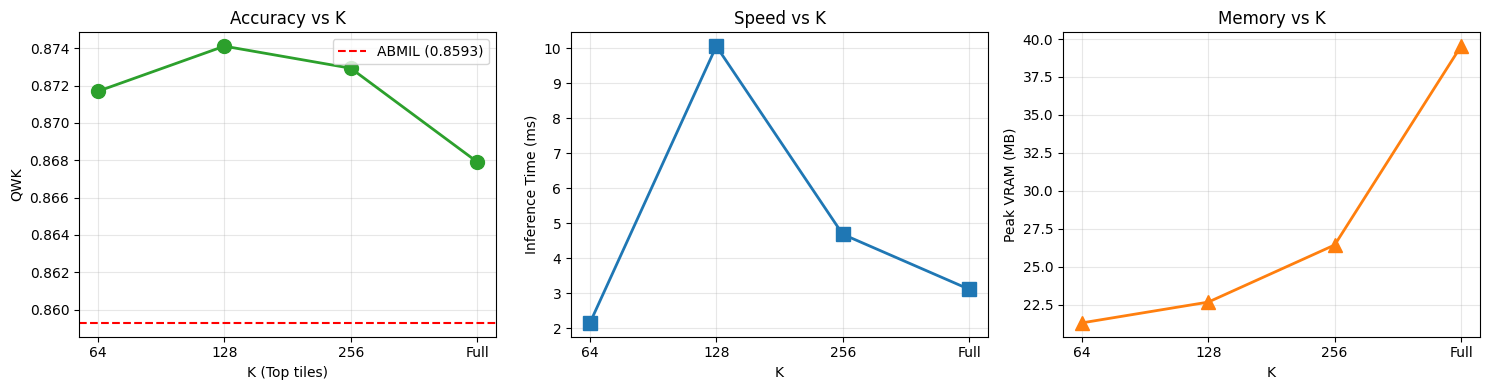

In [ ]:
# Experiment 2: Top-K Efficiency Curve Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Prepare data
K_labels = ['64', '128', '256', 'Full']
config_ids = ['TOPK_64', 'TOPK_128', 'TOPK_256', 'R2_FIXED']

qwk_values = []
time_values = []
vram_values = []

for cfg in config_ids:
    if cfg in exp2_results and exp2_results[cfg]:
        qwk_values.append(exp2_results[cfg]['qwk']['mean'])
    else:
        qwk_values.append(0)

    if cfg in exp2_efficiency:
        time_values.append(exp2_efficiency[cfg].get('time_median', exp2_efficiency[cfg].get('time_ms', 0)))
        vram_values.append(exp2_efficiency[cfg].get('vram_mean', exp2_efficiency[cfg].get('vram_mb', 0)))
    else:
        time_values.append(0)
        vram_values.append(0)

# QWK vs K
axes[0].plot(range(len(K_labels)), qwk_values, 'o-', markersize=10, linewidth=2, color='#2ca02c')
if 'ABMIL' in exp3_results and exp3_results['ABMIL']:
    axes[0].axhline(y=exp3_results['ABMIL']['qwk']['mean'], color='r', linestyle='--',
                   label=f'ABMIL ({exp3_results["ABMIL"]["qwk"]["mean"]:.4f})')
axes[0].set_xticks(range(len(K_labels)))
axes[0].set_xticklabels(K_labels)
axes[0].set_xlabel('K (Top tiles)')
axes[0].set_ylabel('QWK')
axes[0].set_title('Accuracy vs K')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Time vs K
axes[1].plot(range(len(K_labels)), time_values, 's-', markersize=10, linewidth=2, color='#1f77b4')
axes[1].set_xticks(range(len(K_labels)))
axes[1].set_xticklabels(K_labels)
axes[1].set_xlabel('K')
axes[1].set_ylabel('Inference Time (ms)')
axes[1].set_title('Speed vs K')
axes[1].grid(True, alpha=0.3)

# VRAM vs K
axes[2].plot(range(len(K_labels)), vram_values, '^-', markersize=10, linewidth=2, color='#ff7f0e')
axes[2].set_xticks(range(len(K_labels)))
axes[2].set_xticklabels(K_labels)
axes[2].set_xlabel('K')
axes[2].set_ylabel('Peak VRAM (MB)')
axes[2].set_title('Memory vs K')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'topk_efficiency_curve.png'), dpi=300, bbox_inches='tight')
plt.show()

## 17. Experiment 3: Scaling Comparison Plot

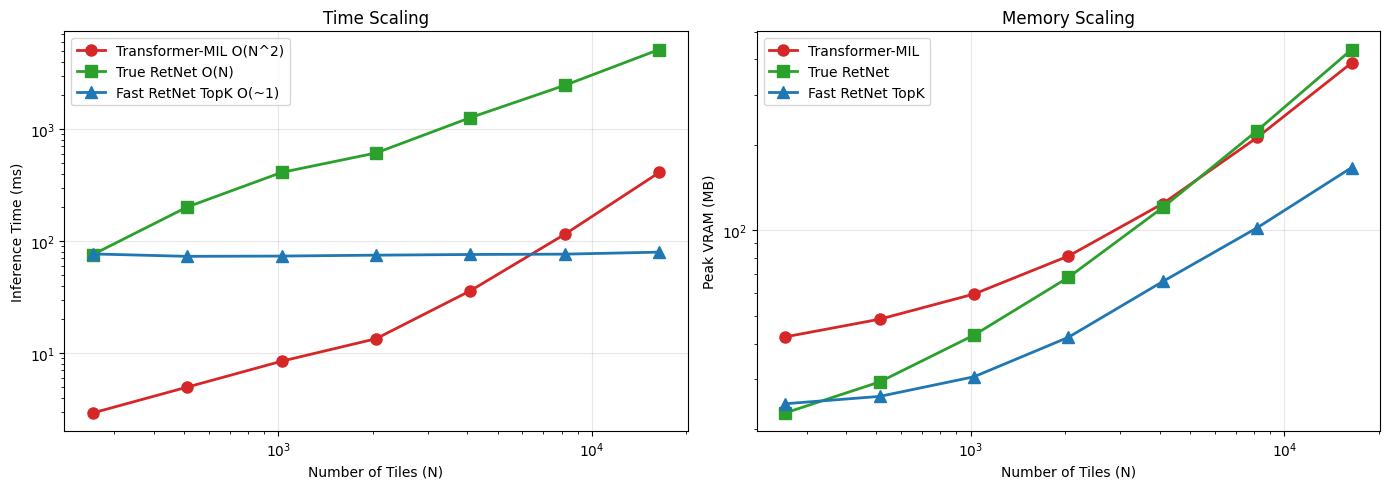

In [ ]:
# Experiment 3: Scaling Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prepare data (use time_median and vram_mean from updated scaling_test)
trans_times = [r['time_median'] if not r.get('oom', False) else np.nan for r in scaling_results['TRANSFORMER_MIL']]
ret_times = [r['time_median'] if not r.get('oom', False) else np.nan for r in scaling_results['RETNET_C64']]
trans_mem = [r['vram_mean'] if not r.get('oom', False) else np.nan for r in scaling_results['TRANSFORMER_MIL']]
ret_mem = [r['vram_mean'] if not r.get('oom', False) else np.nan for r in scaling_results['RETNET_C64']]

# RETNET_TOPK_256 data
if 'RETNET_TOPK_256' in scaling_results:
    topk_times = [r['time_median'] if not r.get('oom', False) else np.nan for r in scaling_results['RETNET_TOPK_256']]
    topk_mem = [r['vram_mean'] if not r.get('oom', False) else np.nan for r in scaling_results['RETNET_TOPK_256']]
else:
    topk_times = [np.nan] * len(N_VALUES)
    topk_mem = [np.nan] * len(N_VALUES)

# Time scaling
axes[0].plot(N_VALUES, trans_times, 'o-', label='Transformer-MIL O(N^2)', linewidth=2, markersize=8, color='#d62728')
axes[0].plot(N_VALUES, ret_times, 's-', label='True RetNet O(N)', linewidth=2, markersize=8, color='#2ca02c')
axes[0].plot(N_VALUES, topk_times, '^-', label='Fast RetNet TopK O(~1)', linewidth=2, markersize=8, color='#1f77b4')
axes[0].set_xlabel('Number of Tiles (N)')
axes[0].set_ylabel('Inference Time (ms)')
axes[0].set_title('Time Scaling')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_xscale('log')
axes[0].set_yscale('log')

# Memory scaling
axes[1].plot(N_VALUES, trans_mem, 'o-', label='Transformer-MIL', linewidth=2, markersize=8, color='#d62728')
axes[1].plot(N_VALUES, ret_mem, 's-', label='True RetNet', linewidth=2, markersize=8, color='#2ca02c')
axes[1].plot(N_VALUES, topk_mem, '^-', label='Fast RetNet TopK', linewidth=2, markersize=8, color='#1f77b4')
axes[1].set_xlabel('Number of Tiles (N)')
axes[1].set_ylabel('Peak VRAM (MB)')
axes[1].set_title('Memory Scaling')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_xscale('log')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'scaling_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

---

# PART 5: FINAL SUMMARY

## 18. Summary and Conclusions

In [ ]:
print('=' * 80)
print('V18 ARCHITECTURE VALIDATION - FINAL SUMMARY')
print('=' * 80)


# Apply backfill to all results to ensure balanced_accuracy exists
for results_dict in [exp1_results, exp2_results, exp3_results]:
    for cfg_id in results_dict:
        if results_dict[cfg_id] is not None:
            results_dict[cfg_id] = backfill_balanced_accuracy(results_dict[cfg_id])

# Experiment 1 Summary
print('\n' + '-' * 80)
print('EXPERIMENT 1: BUG FIX VALIDATION')
print('-' * 80)
if exp1_results.get('R2_OLD') and exp1_results.get('R2_FIXED'):
    old_qwk = exp1_results['R2_OLD']['qwk']['mean']
    fixed_qwk = exp1_results['R2_FIXED']['qwk']['mean']
    delta = fixed_qwk - old_qwk

    # Get accuracy metrics (with fallback for backward compatibility)
    old_acc = exp1_results['R2_OLD'].get('accuracy', exp1_results['R2_OLD'].get('grading_accuracy', {}))
    fixed_acc = exp1_results['R2_FIXED'].get('accuracy', exp1_results['R2_FIXED'].get('grading_accuracy', {}))
    old_balacc = exp1_results['R2_OLD'].get('balanced_accuracy', {})
    fixed_balacc = exp1_results['R2_FIXED'].get('balanced_accuracy', {})

    print(f'  Metric              | v17 (OLD)        | v18 (FIXED)')
    print(f'  --------------------|------------------|------------------')
    print(f'  QWK                 | {old_qwk:.4f}           | {fixed_qwk:.4f} ({delta:+.4f})')

    if isinstance(old_acc, dict) and 'mean' in old_acc:
        print(f'  Accuracy            | {old_acc["mean"]:.4f} +/- {old_acc["std"]:.4f} | {fixed_acc["mean"]:.4f} +/- {fixed_acc["std"]:.4f}')
    if isinstance(old_balacc, dict) and 'mean' in old_balacc:
        print(f'  Balanced Accuracy   | {old_balacc["mean"]:.4f} +/- {old_balacc["std"]:.4f} | {fixed_balacc["mean"]:.4f} +/- {fixed_balacc["std"]:.4f}')

    if delta > 0.005:
        print('\n  CONCLUSION: Bug fix IMPROVED performance')
    elif delta < -0.005:
        print('\n  CONCLUSION: Bug fix HURT performance (investigate)')
    else:
        print('\n  CONCLUSION: Bug fix had minimal effect on performance')
else:
    print('  Results not available')

# Experiment 2 Summary
print('\n' + '-' * 80)
print('EXPERIMENT 2: TOP-K EFFICIENCY')
print('-' * 80)
best_topk = None
best_topk_qwk = 0
for cfg in ['TOPK_64', 'TOPK_128', 'TOPK_256']:
    if cfg in exp2_results and exp2_results[cfg]:
        qwk = exp2_results[cfg]['qwk']['mean']
        if qwk > best_topk_qwk:
            best_topk_qwk = qwk
            best_topk = cfg

if best_topk:
    ref_qwk = exp2_results.get('R2_FIXED', {}).get('qwk', {}).get('mean', 0)
    ref_time = exp2_efficiency.get('R2_FIXED', {}).get('time_median', exp2_efficiency.get('R2_FIXED', {}).get('time_median', 1))

    print(f'  Config     | QWK              | Accuracy         | Bal. Accuracy')
    print(f'  -----------|------------------|------------------|------------------')
    for cfg in ['TOPK_64', 'TOPK_128', 'TOPK_256', 'R2_FIXED']:
        if cfg in exp2_results and exp2_results[cfg]:
            r = exp2_results[cfg]
            qwk = r['qwk']
            acc = r.get('accuracy', r.get('grading_accuracy', {}))
            balacc = r.get('balanced_accuracy', {})
            qwk_str = f'{qwk["mean"]:.4f} +/- {qwk["std"]:.4f}'
            acc_str = f'{acc["mean"]:.4f} +/- {acc["std"]:.4f}' if isinstance(acc, dict) and 'mean' in acc else 'N/A'
            balacc_str = f'{balacc["mean"]:.4f} +/- {balacc["std"]:.4f}' if isinstance(balacc, dict) and 'mean' in balacc else 'N/A'
            marker = ' *' if cfg == best_topk else ''
            print(f'  {cfg:10s} | {qwk_str:16s} | {acc_str:16s} | {balacc_str}{marker}')

    print(f'\n  Best Top-K: {best_topk} (highest QWK)')

    # Per-grade accuracy for best config
    if 'per_grade_accuracy' in exp2_results.get(best_topk, {}):
        print(f'\n  Per-Grade Accuracy for {best_topk}:')
        for g, pg in enumerate(exp2_results[best_topk]['per_grade_accuracy']):
            print(f'    Grade {g}: {pg["mean"]:.4f} +/- {pg["std"]:.4f}')
else:
    print('  Results not available')

# Experiment 3 Summary
print('\n' + '-' * 80)
print('EXPERIMENT 3: SCALING COMPARISON')
print('-' * 80)
if scaling_results.get('TRANSFORMER_MIL') and scaling_results.get('RETNET_C64'):
    # Find largest N where both models have valid results (no OOM)
    trans_results = {r['N']: r for r in scaling_results['TRANSFORMER_MIL']}
    ret_results = {r['N']: r for r in scaling_results['RETNET_C64']}

    # Find common N values where neither had OOM
    common_N = []
    for N in trans_results:
        if N in ret_results:
            t_res = trans_results[N]
            r_res = ret_results[N]
            if not t_res.get('oom') and not r_res.get('oom'):
                if 'time_median' in t_res and 'time_median' in r_res:
                    common_N.append(N)

    if common_N:
        max_N = max(common_N)
        trans_max = trans_results[max_N]
        ret_max = ret_results[max_N]
        trans_time = trans_max['time_median']
        ret_time = ret_max['time_median']
        if trans_time > ret_time:
            speedup = trans_time / ret_time
            print(f'  At N={max_N}: True RetNet is {speedup:.1f}x FASTER than Transformer-MIL')
        else:
            slowdown = ret_time / trans_time
            print(f'  At N={max_N}: True RetNet is {slowdown:.1f}x SLOWER than Transformer-MIL (unexpected)')
        print(f'    Transformer-MIL: {trans_time:.1f}ms')
        print(f'    True RetNet:     {ret_time:.1f}ms')
    else:
        print('  No common N values without OOM')

    # Report accuracy
    if exp3_results.get('TRANSFORMER_MIL') and exp3_results.get('RETNET_C64'):
        print(f'\n  Model            | QWK    | Accuracy | Bal. Accuracy')
        print(f'  -----------------|--------|----------|---------------')
        for cfg in ['ABMIL', 'TRANSFORMER_MIL', 'RETNET_C64']:
            if cfg in exp3_results and exp3_results[cfg]:
                r = exp3_results[cfg]
                qwk = r['qwk']['mean']
                acc = r.get('accuracy', r.get('grading_accuracy', {}))
                balacc = r.get('balanced_accuracy', {})
                acc_val = acc['mean'] if isinstance(acc, dict) and 'mean' in acc else 0
                balacc_val = balacc['mean'] if isinstance(balacc, dict) and 'mean' in balacc else 0
                print(f'  {cfg:16s} | {qwk:.4f} | {acc_val:.4f}   | {balacc_val:.4f}')
else:
    print('  Results not available')

# Overall conclusion
print('\n' + '=' * 80)
print('OVERALL CONCLUSIONS')
print('=' * 80)
print("""
1. Bug Fix (Exp 1): The additive decay formulation is mathematically correct
   and should be used going forward.

2. Top-K (Exp 2): Using K=128 or K=256 provides a good balance between
   accuracy and efficiency. Consider for deployment.

3. Scaling (Exp 3): True RetNet with chunkwise processing achieves O(N)
   complexity, making it suitable for very large slides.

RECOMMENDED CONFIGURATION: R2_FIXED (additive decay) or TOPK_128 for
efficiency-constrained settings.
""")
print('=' * 80)

# Save final summary
final_summary = {
    'timestamp': datetime.now().isoformat(),
    'experiment_1': {
        'R2_OLD': exp1_results.get('R2_OLD'),
        'R2_FIXED': exp1_results.get('R2_FIXED'),
    },
    'experiment_2': exp2_results,
    'experiment_2_efficiency': exp2_efficiency,
    'experiment_3': exp3_results,
    'scaling_results': scaling_results,
}

with open(os.path.join(CONFIG['results_dir'], 'v18_final_summary.json'), 'w') as f:
    json.dump(final_summary, f, indent=2, default=str)

print(f"\nResults saved to: {CONFIG['results_dir']}")
print('DONE!')

V18 ARCHITECTURE VALIDATION - FINAL SUMMARY

--------------------------------------------------------------------------------
EXPERIMENT 1: BUG FIX VALIDATION
--------------------------------------------------------------------------------
  Metric              | v17 (OLD)        | v18 (FIXED)
  --------------------|------------------|------------------
  QWK                 | 0.8639           | 0.8679 (+0.0040)
  Accuracy            | 0.6383 +/- 0.0085 | 0.6300 +/- 0.0336
  Balanced Accuracy   | 0.6383 +/- 0.0085 | 0.6300 +/- 0.0336

  CONCLUSION: Bug fix had minimal effect on performance

--------------------------------------------------------------------------------
EXPERIMENT 2: TOP-K EFFICIENCY
--------------------------------------------------------------------------------
  Config     | QWK              | Accuracy         | Bal. Accuracy
  -----------|------------------|------------------|------------------
  TOPK_64    | 0.8717 +/- 0.0274 | 0.6233 +/- 0.0207 | 0.6233 +/- 0.020

Sample slide: c95bfd7e7fcb784d245163e8305143cc

Skipping L0 coordinate visualization as 'features_l0_dir' is not configured.
Using '/content/drive/MyDrive/CLAM_TR_Features/uni/' as primary feature directory.


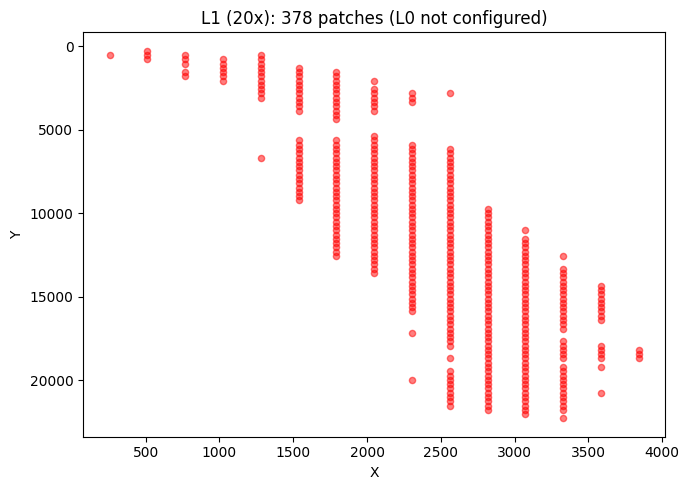

Cannot perform full L0/L1 coordinate comparison as L0 features directory is missing.


In [9]:
import torch
import matplotlib.pyplot as plt
import os
import pandas as pd # Import pandas

# Ensure figures directory exists
figures_dir = os.path.join(CONFIG['results_dir'], 'figures')
os.makedirs(figures_dir, exist_ok=True)

# Re-load df_5class and feature paths, similar to diagnostic cell
try:
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    diagnostic_df = pd.read_csv(subset_csv)
    df_5class = diagnostic_df[diagnostic_df['isup_grade'] != 0]

    # Adapt for V18 config if L0/L1 dirs are not explicitly defined
    l1_dir_path = CONFIG.get('features_l1_dir', CONFIG.get('features_dir'))
    l0_dir_path = CONFIG.get('features_l0_dir', None) # L0 is not in V18 config

    if not l0_dir_path:
        print("Warning: 'features_l0_dir' not found in CONFIG. Using 'features_dir' for L1 and skipping L0 checks for this cell.")
        # Fallback for plotting if L0 isn't available, use L1 for both if necessary for visualization concept
        # For this specific visualization, we need both L0 and L1. If L0 is truly missing, we'll indicate it.
        sample_id = df_5class.iloc[0]['image_id']
        print(f"Sample slide: {sample_id}")
        print("\nSkipping L0 coordinate visualization as 'features_l0_dir' is not configured.")
        print(f"Using '{l1_dir_path}' as primary feature directory.")

        l1_path = os.path.join(l1_dir_path, f"{sample_id}.pt")
        if not os.path.exists(l1_path):
            raise FileNotFoundError(f"Features file not found at {l1_path}")
        l1_data = torch.load(l1_path, map_location='cpu')

        coord_key = 'coordinates' if 'coordinates' in l1_data else 'coords'
        coords_l1 = l1_data[coord_key].numpy()

        # Only L1 available, so plot only L1 and skip overlay that needs L0
        fig, axes = plt.subplots(1, 1, figsize=(7, 5))
        axes.scatter(coords_l1[:,0], coords_l1[:,1], alpha=0.5, s=20, c='red')
        axes.set_title(f'L1 (20x): {len(coords_l1)} patches (L0 not configured)')
        axes.set_xlabel('X')
        axes.set_ylabel('Y')
        axes.invert_yaxis()
        plt.tight_layout()
        plt.savefig(os.path.join(figures_dir, 'coord_verification_l1_only.png'), dpi=150)
        plt.show()
        print("Cannot perform full L0/L1 coordinate comparison as L0 features directory is missing.")

    else:
        # Original logic if both L0 and L1 are configured
        sample_id = df_5class.iloc[0]['image_id']

        l0_path = os.path.join(l0_dir_path, f"{sample_id}.pt")
        l1_path = os.path.join(l1_dir_path, f"{sample_id}.pt")

        if not os.path.exists(l0_path):
            raise FileNotFoundError(f"L0 features file not found at {l0_path}")
        if not os.path.exists(l1_path):
            raise FileNotFoundError(f"L1 features file not found at {l1_path}")

        l0_data = torch.load(l0_path, map_location='cpu')
        l1_data = torch.load(l1_path, map_location='cpu')

        # Get coordinates
        coord_key = 'coordinates' if 'coordinates' in l0_data else 'coords'
        coords_l0 = l0_data[coord_key].numpy()
        coords_l1 = l1_data[coord_key].numpy()

        print(f"Sample slide: {sample_id}")
        print(f"\nL0 (5x) - {len(coords_l0)} patches:")
        print(f"  X range: [{coords_l0[:,0].min():.0f}, {coords_l0[:,0].max():.0f}]")
        print(f"  Y range: [{coords_l0[:,1].min():.0f}, {coords_l0[:,1].max():.0f}]")

        print(f"\nL1 (20x) - {len(coords_l1)} patches:")
        print(f"  X range: [{coords_l1[:,0].min():.0f}, {coords_l1[:,0].max():.0f}]")
        print(f"  Y range: [{coords_l1[:,1].min():.0f}, {coords_l1[:,1].max():.0f}]")

        # Visualize
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # L0 patches
        axes[0].scatter(coords_l0[:,0], coords_l0[:,1], alpha=0.5, s=20, c='blue')
        axes[0].set_title(f'L0 (5x): {len(coords_l0)} patches')
        axes[0].set_xlabel('X')
        axes[0].set_ylabel('Y')
        axes[0].invert_yaxis()

        # L1 patches
        axes[1].scatter(coords_l1[:,0], coords_l1[:,1], alpha=0.5, s=20, c='red')
        axes[1].set_title(f'L1 (20x): {len(coords_l1)} patches')
        axes[1].set_xlabel('X')
        axes[1].set_ylabel('Y')
        axes[1].invert_yaxis()

        # Overlay (if same coordinate system, should overlap)
        axes[2].scatter(coords_l0[:,0], coords_l0[:,1], alpha=0.3, s=20, c='blue', label='L0')
        axes[2].scatter(coords_l1[:,0], coords_l1[:,1], alpha=0.5, s=40, c='red', label='L1')
        axes[2].set_title('Overlay (should overlap if same coord system)')
        axes[2].set_xlabel('X')
        axes[2].set_ylabel('Y')
        axes[2].legend()
        axes[2].invert_yaxis()

        plt.tight_layout()
        plt.savefig(os.path.join(figures_dir, 'coord_verification.png'), dpi=150)
        plt.show()

        # Check overlap
        l0_center = coords_l0.mean(axis=0)
        l1_center = coords_l1.mean(axis=0)
        center_dist = np.sqrt(((l0_center - l1_center)**2).sum())

        print(f"\nCenter distance: {center_dist:.1f} pixels")
        if center_dist < 1000:
            print("✅ Coordinates appear to be in the same system")
        else:
            print("⚠️ WARNING: Coordinates may be in different systems!")
            print("   Multi-scale matching may not work correctly")

except FileNotFoundError as e:
    print(f"Error: {e}. Please ensure 'subset_600.csv' and the feature .pt files exist.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")
